In [34]:
import matplotlib.pyplot as plt
import pandas as pd
import json
import ast
import matplotlib.dates as mdates
import numpy as np
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from pathlib import Path
from statsmodels.tsa.stattools import adfuller, kpss
from copy import deepcopy

In [2]:
df_export_europe = pd.read_csv(r"D:\research\datasets_europe\export.csv")
df_import_europe = pd.read_csv(r"D:\research\datasets_europe\import.csv")
df_gen_europe = pd.read_csv(r"D:\research\datasets_europe\generation.csv")
df_forecast_europe = pd.read_csv(r"D:\research\datasets_europe\load_forecast.csv")
df_load_europe = pd.read_csv(r"D:\research\datasets_europe\load.csv")

C:\Users\Robert\AppData\Local\Temp\ipykernel_22656\1532648590.py:3: DtypeWarning: Columns (26: ('country', ''), 48: country) have mixed types. Specify dtype option on import or set low_memory=False.
  df_gen_europe = pd.read_csv(r"D:\research\datasets_europe\generation.csv")


In [3]:
df_forecast_USA = pd.read_csv(r"D:\research\datasets_USA\dayahead_forecast.csv")
df_demand_USA = pd.read_csv(r"D:\research\datasets_USA\demand.csv")
df_netgen_USA = pd.read_csv(r"D:\research\datasets_USA\net_generation.csv")
df_inter_USA = pd.read_csv(r"D:\research\datasets_USA\Total_interchange.csv")



## Работа с пропусками

In [4]:
counts=df_forecast_USA["respondent"].value_counts()
df_forecast_USA=df_forecast_USA[df_forecast_USA["respondent"].isin(counts[counts >= 60000].index)]

counts=df_demand_USA["respondent"].value_counts()
df_demand_USA=df_demand_USA[df_demand_USA["respondent"].isin(counts[counts >= 55000].index)]

counts=df_netgen_USA["respondent"].value_counts()
df_netgen_USA = df_netgen_USA[df_netgen_USA["respondent"].isin(counts[counts >= 55000].index)]
# тут мы почистили явно странные данные, тут по рядам пока получаются нормальные данные.Проблем вроде именно с рядами США нет 
# важно сказать что мы почистили данные , так как там во многом обоснованные пропуски , в том смысле , что электрокомпании могли уйти с рынка , или наоборот появится на нем слишком поздно 



In [5]:
df_gen_europe["('country', '')"]=df_gen_europe["('country', '')"].fillna("PL")
df_gen_europe=df_gen_europe.drop(columns = ["country"]).rename(columns = {"('country', '')":"country"})

mask = df_gen_europe["country"] == "PL"
for column in df_gen_europe.columns:
    if column.startswith("("):
        short,kind=ast.literal_eval(column)
        if kind=="Actual Aggregated" and short in df_gen_europe.columns:
            df_gen_europe.loc[mask,column]=(df_gen_europe.loc[mask,column].fillna(df_gen_europe.loc[mask,short]))
            
df_gen_europe = df_gen_europe.drop(columns = ['Biomass',
       'Fossil Brown coal/Lignite', 'Fossil Coal-derived gas', 'Fossil Gas',
       'Fossil Hard coal', 'Fossil Oil', 'Hydro Pumped Storage',
       'Hydro Run-of-river and pondage', 'Hydro Water Reservoir',
       'Wind Onshore', 'Solar', 'Other renewable', 'Other'])



**Проблемы с пропусками по generation датасету**

* Дальше с пропусками возника серьезная проблема, где-то пропуски были в местах означающих 0 генерацию.Это однозначно хорошо можно отселдить на пропускам в Италии, Польше и Германии по атомной энергетике.В Польше и Италии генерация отсутсвует на всем исследуемом периоде , а в Германии атомная генерация отсутвует именно с 16 апреля 2023 , так как 15 был отключен последний энергоблок.Такая же картина например наблюдается в Италии по гезерной генерации.И поэтому мы приняли решение , что те наблюдения , у которых отсутвует уж очень много наблюдений последовательно , будем просто заменять 0, так как считаем там генерацию нулевой

* Потом все равно остались достаточно большие пропуски  по парам ("FR", "('Wind Offshore', 'Actual Aggregated')") ,("IT", "('Hydro Pumped Storage', 'Actual Aggregated')"),("IT", "('Energy storage', 'Actual Aggregated')"),("IT", "('Fossil Hard coal', 'Actual Aggregated')"),("UK", "('Solar', 'Actual Aggregated')").Код генерировал ChatGPt по следующему описанию:"Сделай код , который для пар country /фича , будет брать последний известный недельный период, переводить этот период в приросты , и потом возвращать эти приросты в период пропусков уже в иисходных числах"

* Дальше мы заполняли пропуски уже просто по дефолту форвард филом , так как больших пропусков там не осталось , и это были в основном микро пропуски с небольше , чем полуднем пропусков 

* Также мы удаллили consumption столбцы , так как (~~с этими столбцами было еще больше проблем в контексте целостности данных~~) мы решили , что не будем анализировать, сколько элекроэнергии тратится на генерацию.(электрогненерация также требует потребления электричества)

In [6]:
df_gen_europe = df_gen_europe.drop(columns=[col for col in df_gen_europe.columns if "Actual Consumption" in col])

In [7]:
columns = df_gen_europe.select_dtypes(include="number").columns
for column in columns:
    mask=df_gen_europe[column].isna()
    groups=mask.groupby(df_gen_europe["country"]).transform(lambda x:x.ne(x.shift()).cumsum())
    length=mask.groupby([df_gen_europe["country"],groups]).transform("size")
    df_gen_europe.loc[mask&(length>10000),column]=0

In [8]:
targets = [
    ("FR", "('Wind Offshore', 'Actual Aggregated')"),
    ("IT", "('Hydro Pumped Storage', 'Actual Aggregated')"),
    ("IT", "('Energy storage', 'Actual Aggregated')"),
    ("IT", "('Fossil Hard coal', 'Actual Aggregated')"),
    ("UK", "('Solar', 'Actual Aggregated')"),]
time_col = "Unnamed: 0"
for country, column in targets:
    positions = np.flatnonzero(df_gen_europe["country"].eq(country).to_numpy())
    times = pd.to_datetime(
        df_gen_europe.iloc[positions][time_col],
        utc=True)
    order=np.argsort(times.to_numpy())
    positions = positions[order]
    times = pd.DatetimeIndex(times.iloc[order])

    if times.has_duplicates:
        raise ValueError(f"{country}: есть повторяющиеся временные отметки")

    # История берётся из исходных значений этого ряда:
    # уже восстановленные в цикле блоки не используются как образец.
    original = pd.Series(
        df_gen_europe.iloc[positions][column].to_numpy(),
        index=times,
        dtype="float64",
    )

    missing = original.isna().to_numpy()
    edges = np.diff(np.r_[False, missing, False].astype(int))
    starts = np.flatnonzero(edges == 1)
    ends = np.flatnonzero(edges == -1)

    column_pos = df_gen_europe.columns.get_loc(column)
    filled_blocks = 0
    skipped_blocks = 0

    for start, end in zip(starts, ends):
        if end - start <= 4:
            continue

        # Нужно известное значение непосредственно перед разрывом
        if start == 0 or pd.isna(original.iloc[start - 1]):
            skipped_blocks += 1
            continue

        # Проверяем, что интервалы внутри разрыва одинаковые
        block_times = times[start:end]
        step = block_times[0] - times[start - 1]

        expected = pd.date_range(
            start=times[start - 1],
            periods=len(block_times) + 1,
            freq=step,
        )

        if step <= pd.Timedelta(0) or not expected.equals(
            times[start - 1:end]
        ):
            skipped_blocks += 1
            continue

        # Включаем точку перед разрывом: она нужна для первого прироста
        target_times = times[start - 1:end]
        max_weeks = int(
            (target_times[0] - times[0]) // pd.Timedelta(weeks=1)
        )

        restored = None

        for weeks_back in range(1, max_weeks + 1):
            reference_times = target_times - pd.Timedelta(weeks=weeks_back)

            # Образец должен целиком находиться до восстанавливаемого блока
            if reference_times[-1] >= block_times[0]:
                continue

            reference = original.reindex(reference_times)

            if reference.isna().any():
                continue

            increments = np.diff(reference.to_numpy())
            candidate = original.iloc[start - 1] + np.cumsum(increments)

            # Для генерации не записываем отрицательные значения
            if np.isfinite(candidate).all() and (candidate >= 0).all():
                restored = candidate
                break

        if restored is None:
            skipped_blocks += 1
            continue

        df_gen_europe.iloc[positions[start:end], column_pos] = restored
        filled_blocks += 1

    print(f"{country} | {column}: "f"заполнено блоков — {filled_blocks}, "f"не удалось заполнить — {skipped_blocks}")
    

FR | ('Wind Offshore', 'Actual Aggregated'): заполнено блоков — 44, не удалось заполнить — 2
IT | ('Hydro Pumped Storage', 'Actual Aggregated'): заполнено блоков — 1014, не удалось заполнить — 48
IT | ('Energy storage', 'Actual Aggregated'): заполнено блоков — 1098, не удалось заполнить — 1
IT | ('Fossil Hard coal', 'Actual Aggregated'): заполнено блоков — 23, не удалось заполнить — 0
UK | ('Solar', 'Actual Aggregated'): заполнено блоков — 70, не удалось заполнить — 5


In [9]:
for country in list(df_gen_europe["country"].unique()):
    mask = (df_gen_europe["country"] == country)
    df_gen_europe.loc[mask] = df_gen_europe.loc[mask].ffill()

In [10]:
df_gen_europe.isna().sum()

Unnamed: 0                                                 0
('Biomass', 'Actual Aggregated')                           0
('Fossil Brown coal/Lignite', 'Actual Aggregated')         0
('Fossil Coal-derived gas', 'Actual Aggregated')           0
('Fossil Gas', 'Actual Aggregated')                        0
('Fossil Hard coal', 'Actual Aggregated')                  0
('Fossil Oil', 'Actual Aggregated')                        0
('Geothermal', 'Actual Aggregated')                        0
('Hydro Pumped Storage', 'Actual Aggregated')              0
('Hydro Run-of-river and pondage', 'Actual Aggregated')    0
('Hydro Water Reservoir', 'Actual Aggregated')             0
('Nuclear', 'Actual Aggregated')                           0
('Other renewable', 'Actual Aggregated')                   0
('Solar', 'Actual Aggregated')                             0
('Waste', 'Actual Aggregated')                             0
('Wind Offshore', 'Actual Aggregated')                     0
('Wind Onshore', 'Actual

**Проблема с пропусками по export/import у UK**

* ТУт возникла проблема с тем , что у Англии есть экспорт и импорт не только с Голандией , Францией и Бельгией , но и с остальными странами Великобритании , а также Данией и Норвегией .Но у нас по ним нет данных, поэтому мы просто опустилии это и мы проосто обьеденили их и посчитали , что это сумма.

* Также тут есть проблема , что например по Франции все данные -это просто часовые данные , но которые расскиданы по 15 минутным , исключительно из-за единого формата скачивания, и чтобы правильно это сохранить тут надо сделать ffill, так как в будущем переводя это в гигават в час, нужно не делить на 4 одинаковые по 15 минут , а просто оставить , как есть, так как эти 15 минутные не сумируются. 

* В будущем очевидно будет приведение к единому формате по datetime.Скорее всего к часовому 

* То же самое делаем для импорта по британии

In [11]:
mask = df_export_europe["country"] == "UK"
df_export_europe.loc[mask , "FR"] =df_export_europe.loc[mask ,"FR"].ffill()
df_export_europe.loc[mask , "BE"] =df_export_europe.loc[mask ,"BE"].ffill()
df_export_europe.loc[mask , "NL"] =df_export_europe.loc[mask ,"NL"].ffill()
df_export_europe.loc[mask , "sum"] =df_export_europe.loc[mask ,["NL","BE","FR"]].sum(axis = 1)

mask = df_import_europe["country"] == "UK"
df_import_europe.loc[mask , "FR"] =df_import_europe.loc[mask ,"FR"].ffill()
df_import_europe.loc[mask , "BE"] =df_import_europe.loc[mask ,"BE"].ffill()
df_import_europe.loc[mask , "NL"] =df_import_europe.loc[mask ,"NL"].ffill()
df_import_europe.loc[mask , "sum"] =df_import_europe.loc[mask ,["NL","BE","FR"]].sum(axis=1)

In [12]:
df_gen_europe = df_gen_europe.rename(columns = {"Unnamed: 0":"data"})
df_gen_europe["data"] = pd.to_datetime(df_gen_europe["data"],format="mixed",utc=True)

df_forecast_europe = df_forecast_europe.rename(columns = {"Unnamed: 0":"data"})
df_forecast_europe["data"] = pd.to_datetime(df_forecast_europe["data"],format="mixed",utc=True)

df_load_europe = df_load_europe.rename(columns = {"Unnamed: 0":"data"})
df_load_europe["data"] = pd.to_datetime(df_load_europe["data"],format="mixed",utc=True)

df_export_europe = df_export_europe.rename(columns = {"Unnamed: 0":"data"})
df_export_europe["data"] = pd.to_datetime(df_export_europe["data"],format="mixed",utc=True)

df_import_europe = df_import_europe.rename(columns = {"Unnamed: 0":"data"})
df_import_europe["data"] = pd.to_datetime(df_import_europe["data"],format="mixed",utc=True)

## Построение графиков

### Европа таргеты

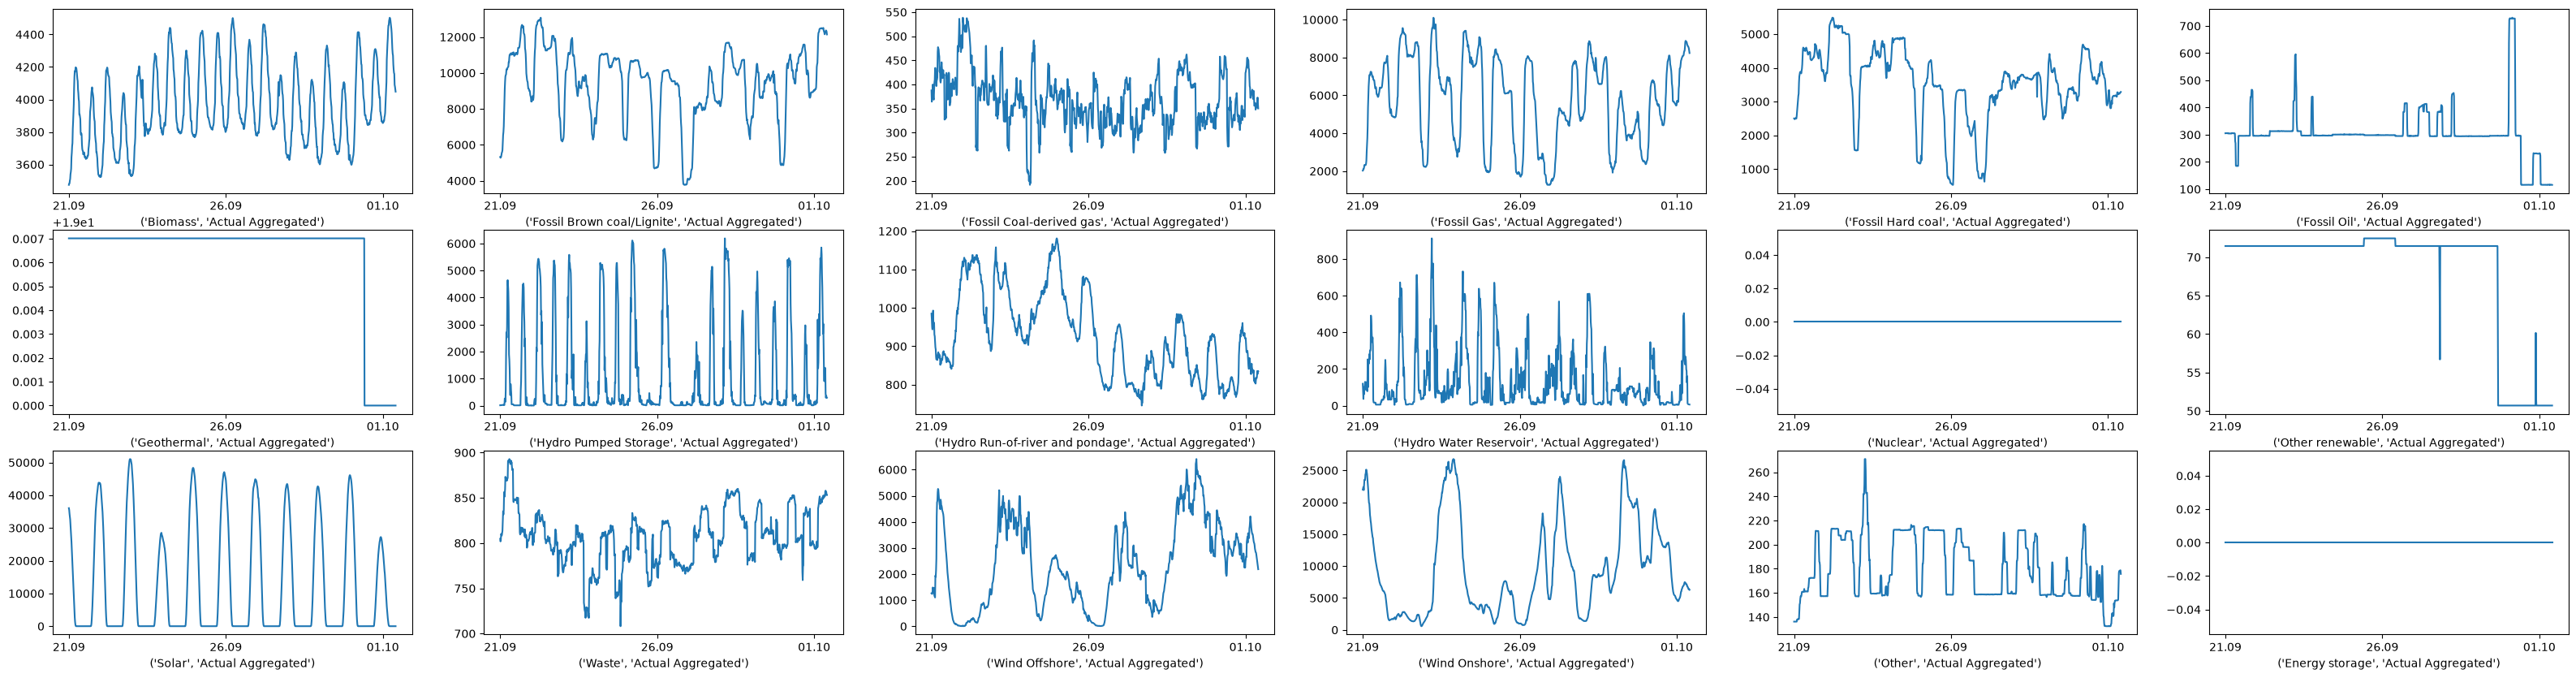

DE_LU


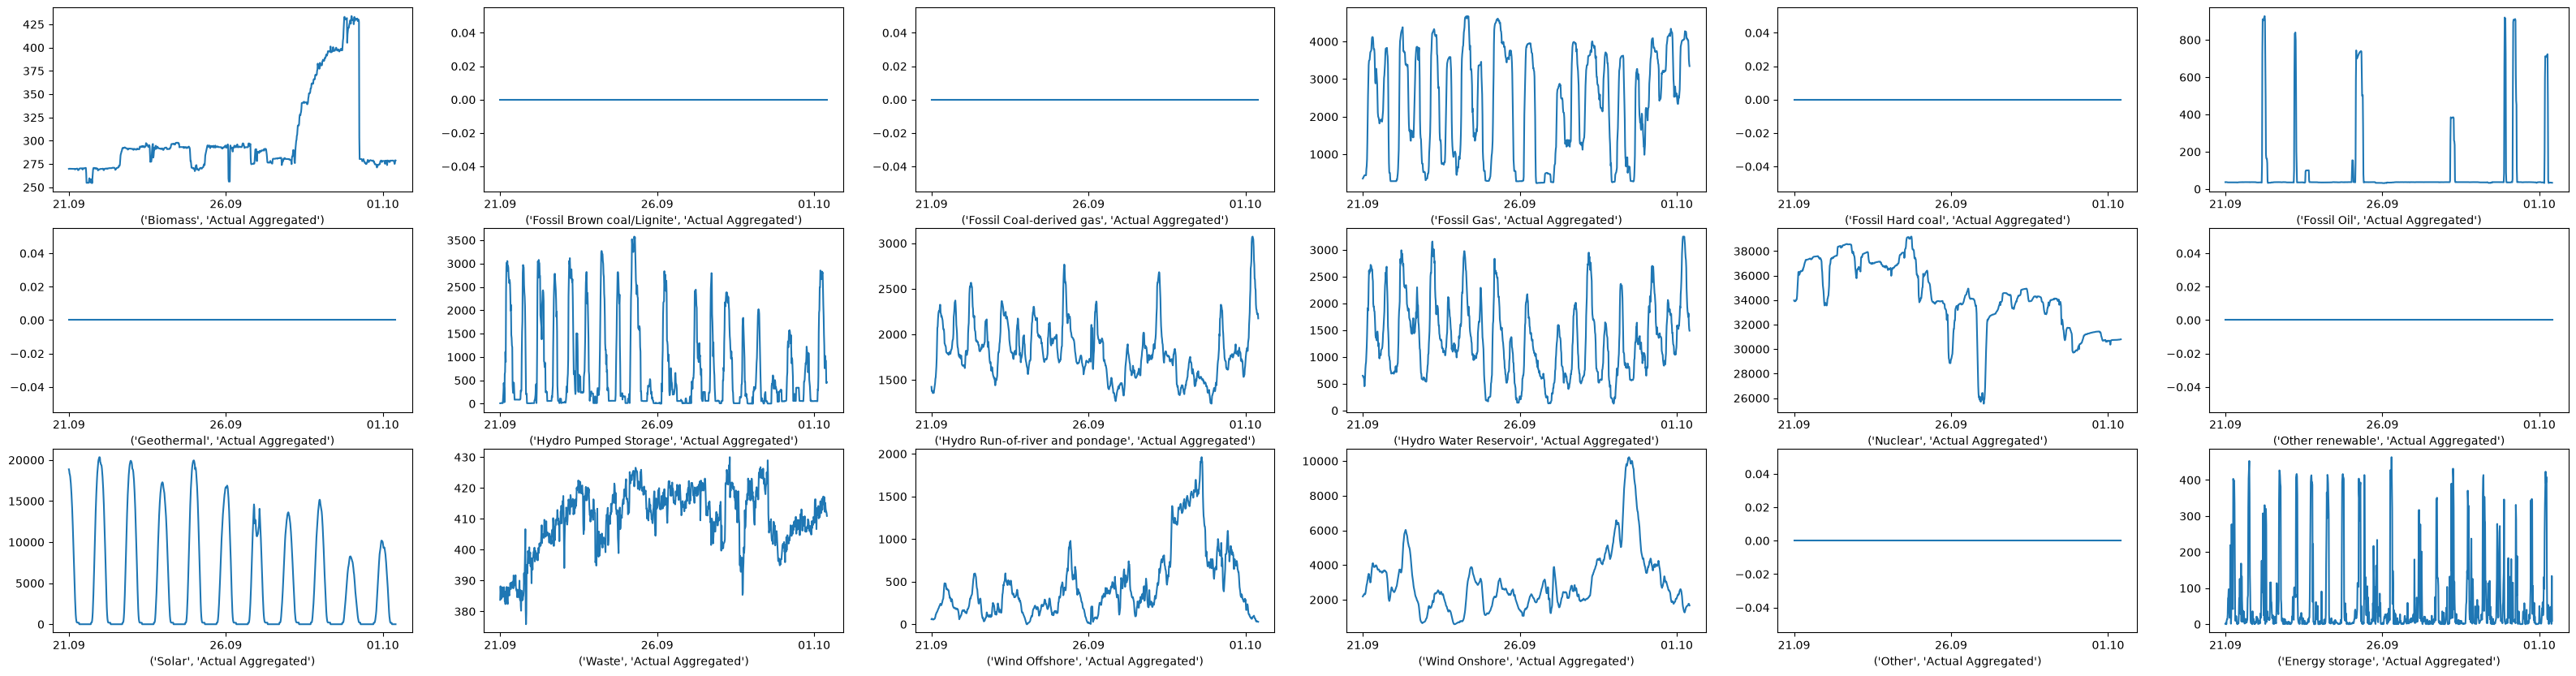

FR


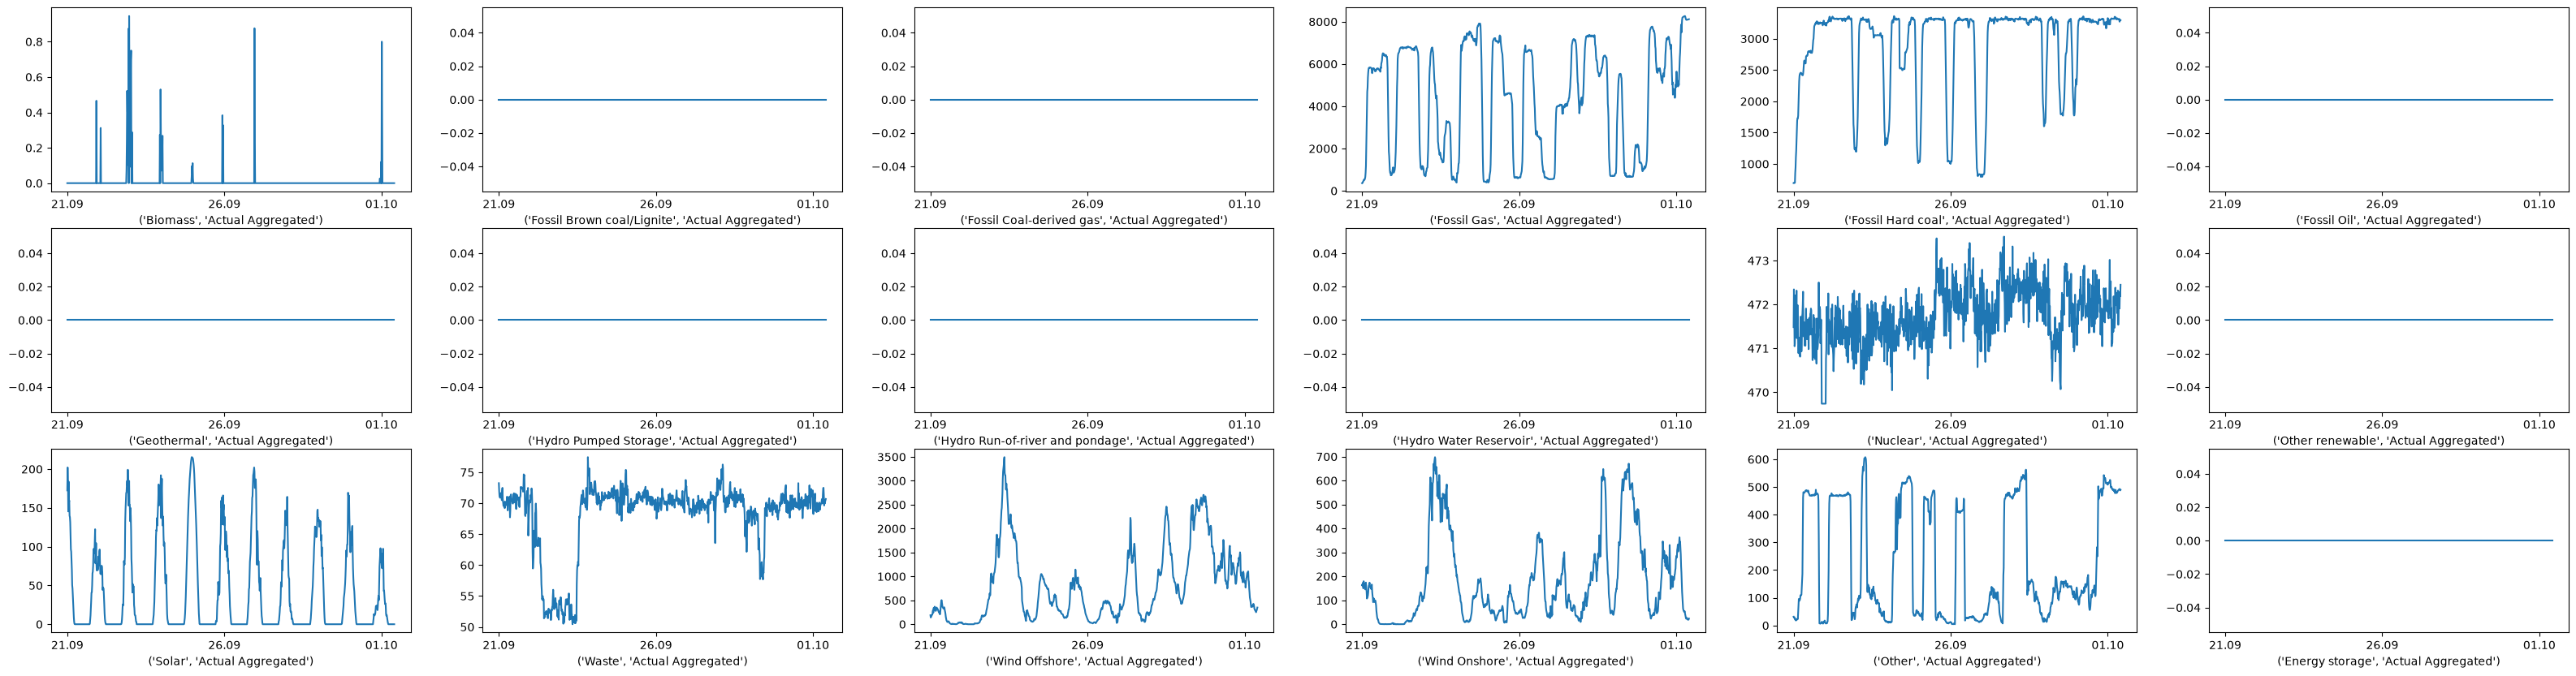

NL


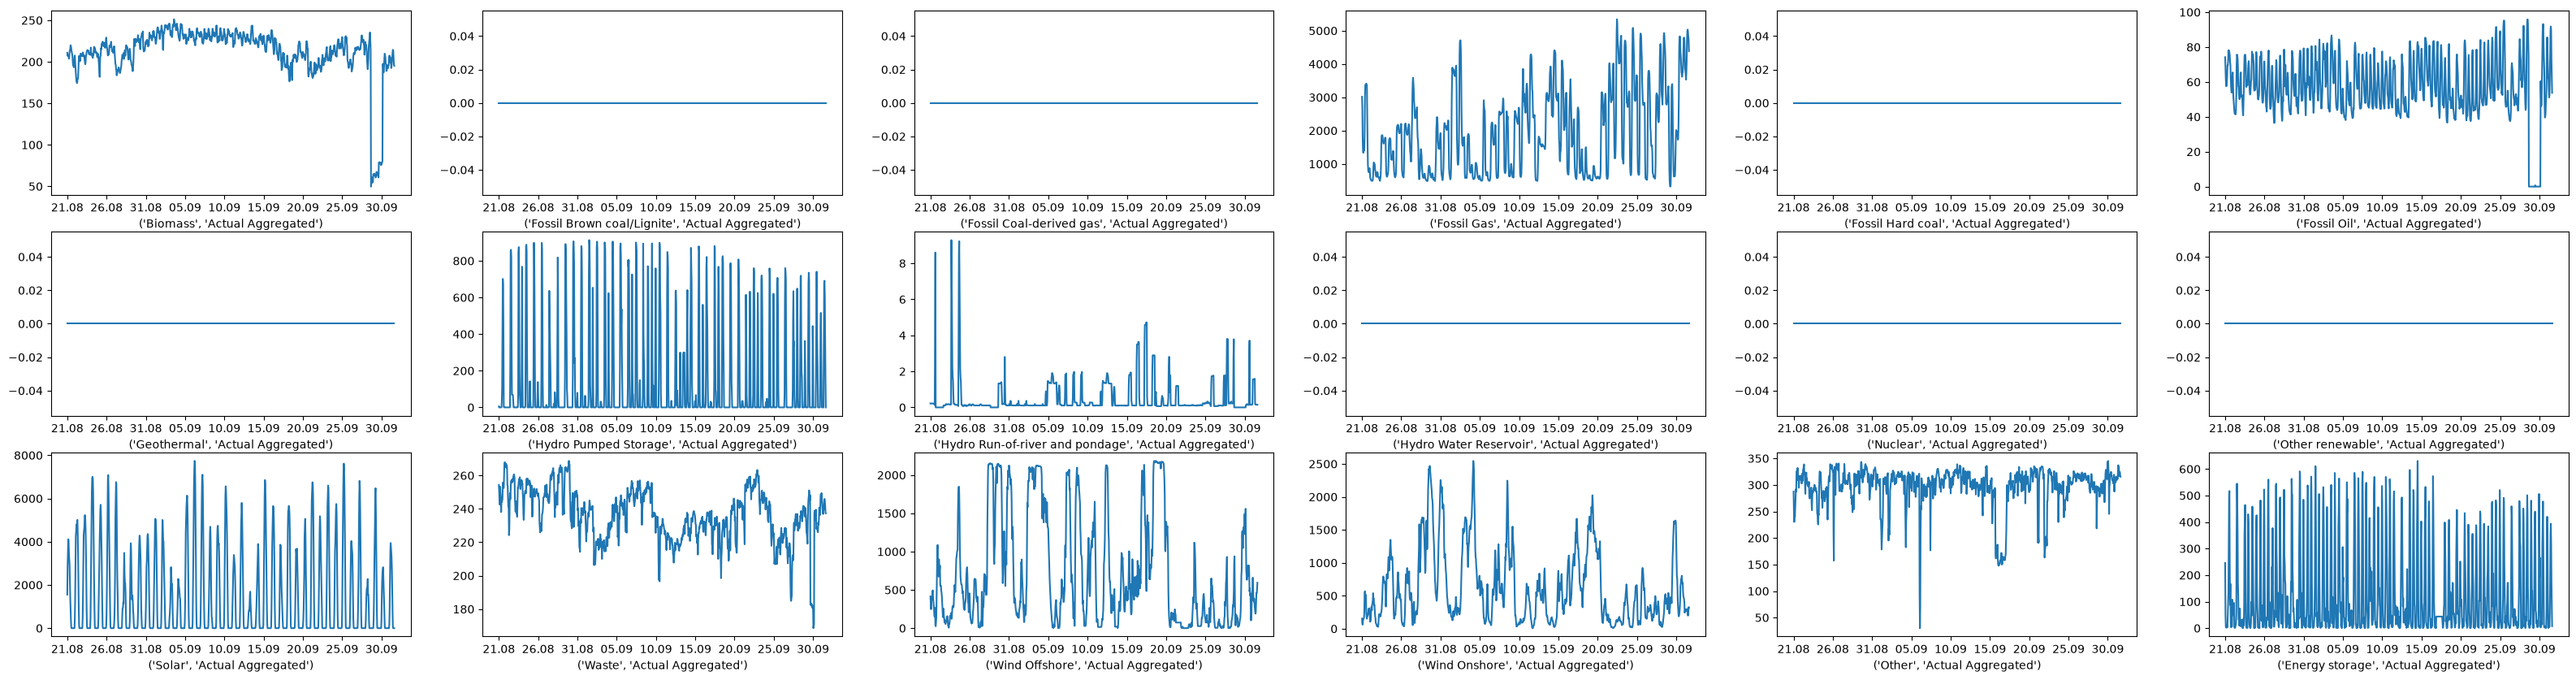

BE


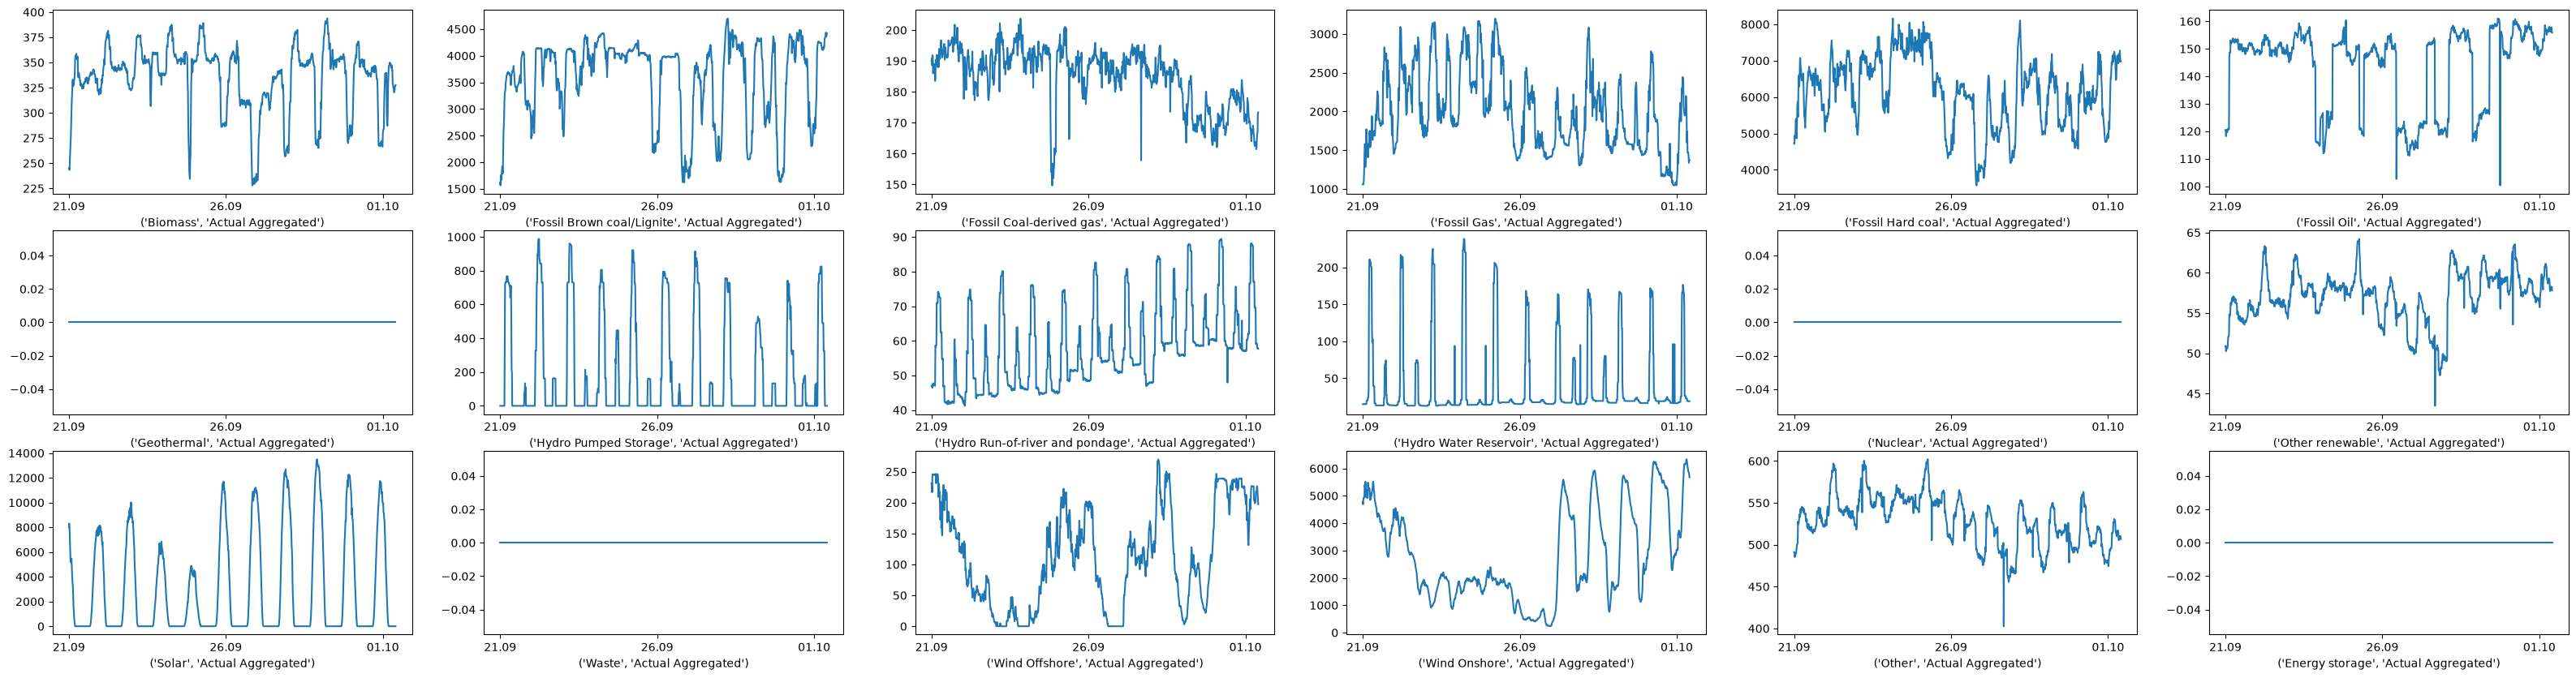

PL


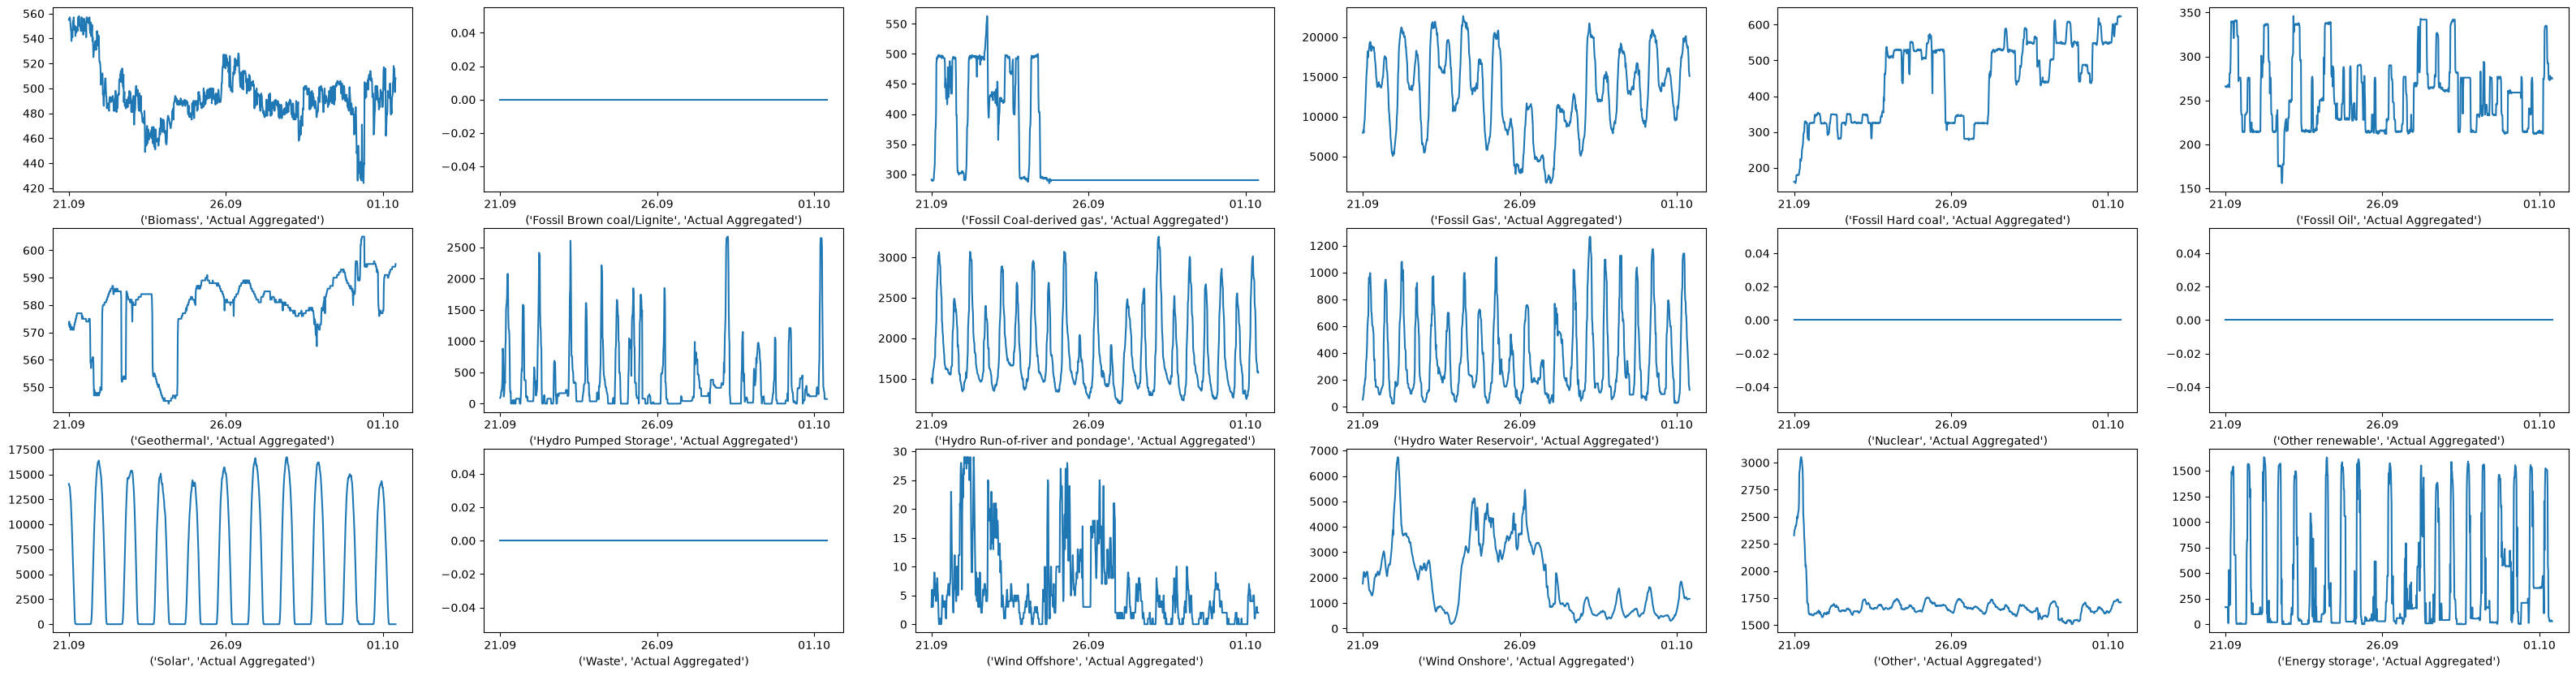

IT


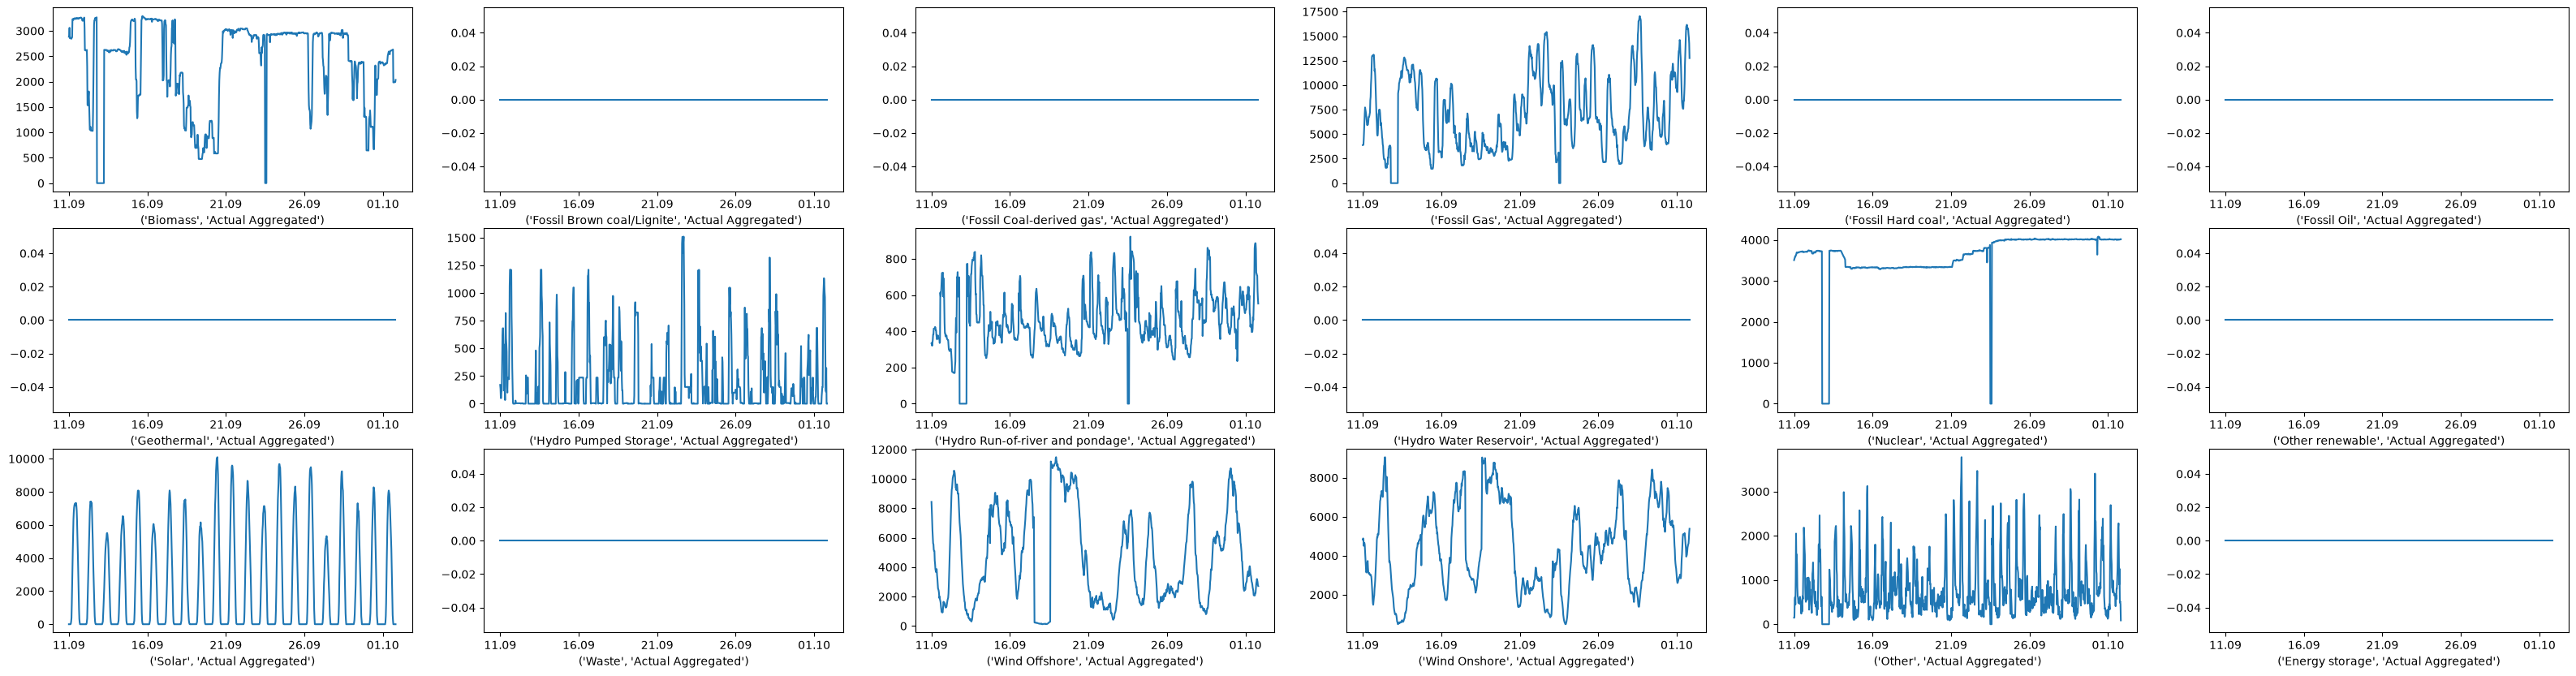

UK


In [13]:
n_cols = len(list(df_gen_europe.columns)) - 2
for i,country in enumerate(list(df_gen_europe["country"].unique())):
    fig, ax = plt.subplots(nrows=3, ncols=6, figsize=(40, 10))
    for j, column in enumerate(df_gen_europe.columns.drop(["country", "data"])):
            if j <= 5 :
                        data = df_gen_europe[df_gen_europe["country"] == country].tail(1000)
                        ax[0][j].plot(data["data"] , data[column]) 
                        ax[0][j].set_xticks(pd.date_range(data["data"].min(), data["data"].max(), freq="5D"))
                        ax[0][j].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
                        ax[0][j].set_xlabel(column)
            if j > 5 and j <= 11:
                        data = df_gen_europe[df_gen_europe["country"] == country].tail(1000)
                        ax[1][j-6].plot(data["data"] , data[column]) 
                        ax[1][j-6].set_xticks(pd.date_range(data["data"].min(), data["data"].max(), freq="5D"))
                        ax[1][j-6].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
                        ax[1][j-6].set_xlabel(column)
            if j > 11:
                        data = df_gen_europe[df_gen_europe["country"] == country].tail(1000)
                        ax[2][j-12].plot(data["data"] , data[column]) 
                        ax[2][j-12].set_xticks(pd.date_range(data["data"].min(), data["data"].max(), freq="5D"))
                        ax[2][j-12].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
                        ax[2][j-12].set_xlabel(column)
    plt.show()
    print(country)
    
            

* Тут мы видим , что по Германии например , генерит большую часть электроэнергии через ветер и солнце, и в целом разнообразие генерации у Герамнии самое большое.

* Известный факт, что Франция первая страна по атомной генерации в Европе , тут мы видим явное подтверждение этому .Пиковая генерация атомом в примерно 4 раза больше ближайщих конкуретнов.

* Нидерланды также генерируют в основном ветром, газом и каменным углем.Остлаьные типы генерации крайне малы.

* В Бельшии также доминируют солнечная, ветровая и газовая энергетика.

* Польша считается странной с одной из самых неэкологичных энергетик.Тут мы опять таки видим этому подтверждение , основная генерация происходит за счет угля.Хотя пиковые значения в солнечной энергетике одни из самых больших в Европе.

В общем можно сказать, что Европа в огромных количествах генерирует электроэнергии через солнце , что очень экологично.

Также тут видно , что далеко не все типы генерации равномерно востребованы в разных странах.Например атомной энергетикой обладают лишь 4 страны , в то время , как из этих 4 стран только Франция генерирует в больших обьемах-это странно, так как в целом атомная энергетика считается настлолько же экологичной , как например газовая генерация , и не сильно хуже , чем солнечная и ветровая.Но ситуации типо Чернобыля и Фукусимы заставили например Герамнию полностью отказаться от атомной генерации.

Также мы видим, и наверняка можем сказать, что скорее всего некоторые данные будут прогнозироваться очень даже сами по себе , например газовая генерация , и текстовые данные для них будут не очень полезны , есть данные , которые скорее всего сами по себе плохо будут прогнозироваться , например бензиновая во Франции.Однако например большая доля генерации солнечной интересна нам в контексте задачи нашей.Очевидно , что погода сильно влияет не этот типи генерации.И сможем ли мы найти какой-то структурный подход обозначить для модели это, это большой вопрос.



DE_LU
FR
NL
BE
PL
IT
UK


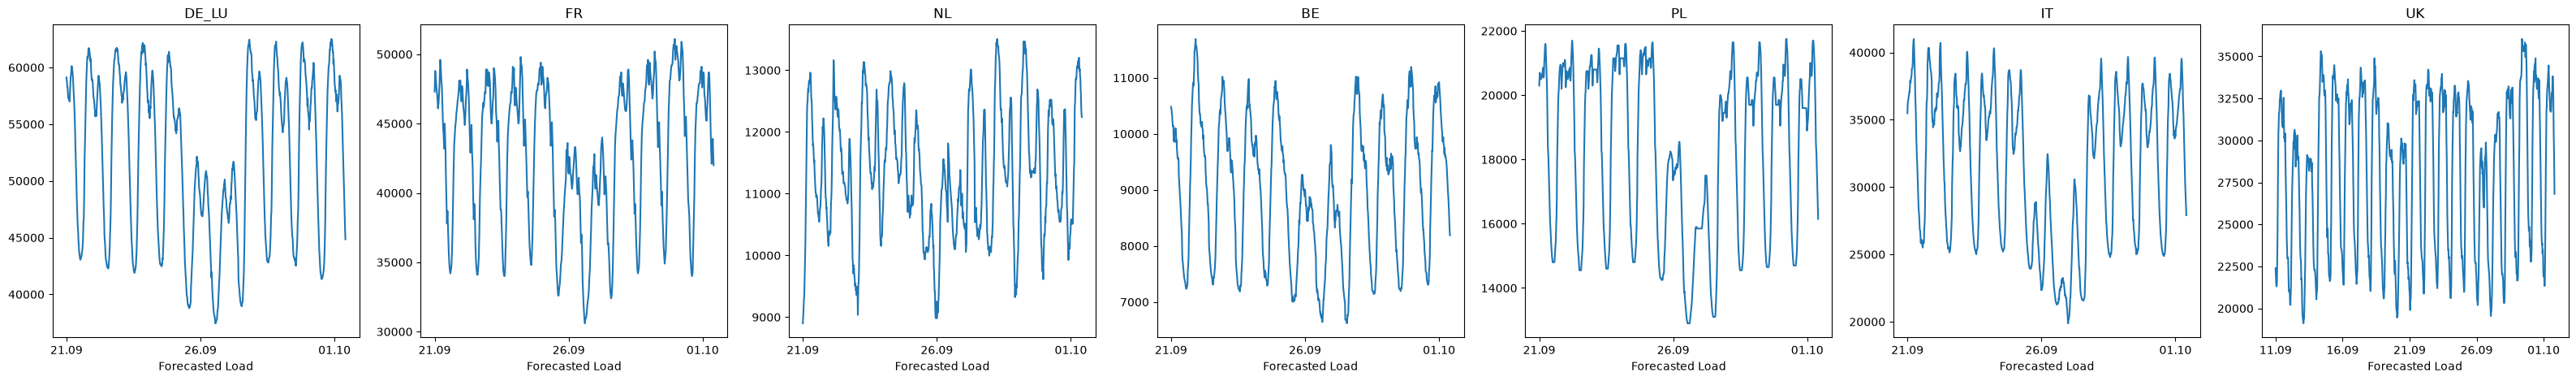

In [14]:
fig, ax = plt.subplots(nrows=1, ncols=7, figsize=(40, 5))
for i,country in enumerate(list(df_forecast_europe["country"].unique())):
    data = df_forecast_europe[df_forecast_europe["country"] == country].tail(1000)
    ax[i].plot(data["data"] , data["Forecasted Load"]) 
    ax[i].set_xticks(pd.date_range(data["data"].min(), data["data"].max(), freq="5D"))
    ax[i].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    ax[i].set_xlabel("Forecasted Load")
    ax[i].set_title(country)
    print(country)
plt.show()

DE_LU
FR
NL
BE
PL
IT
UK


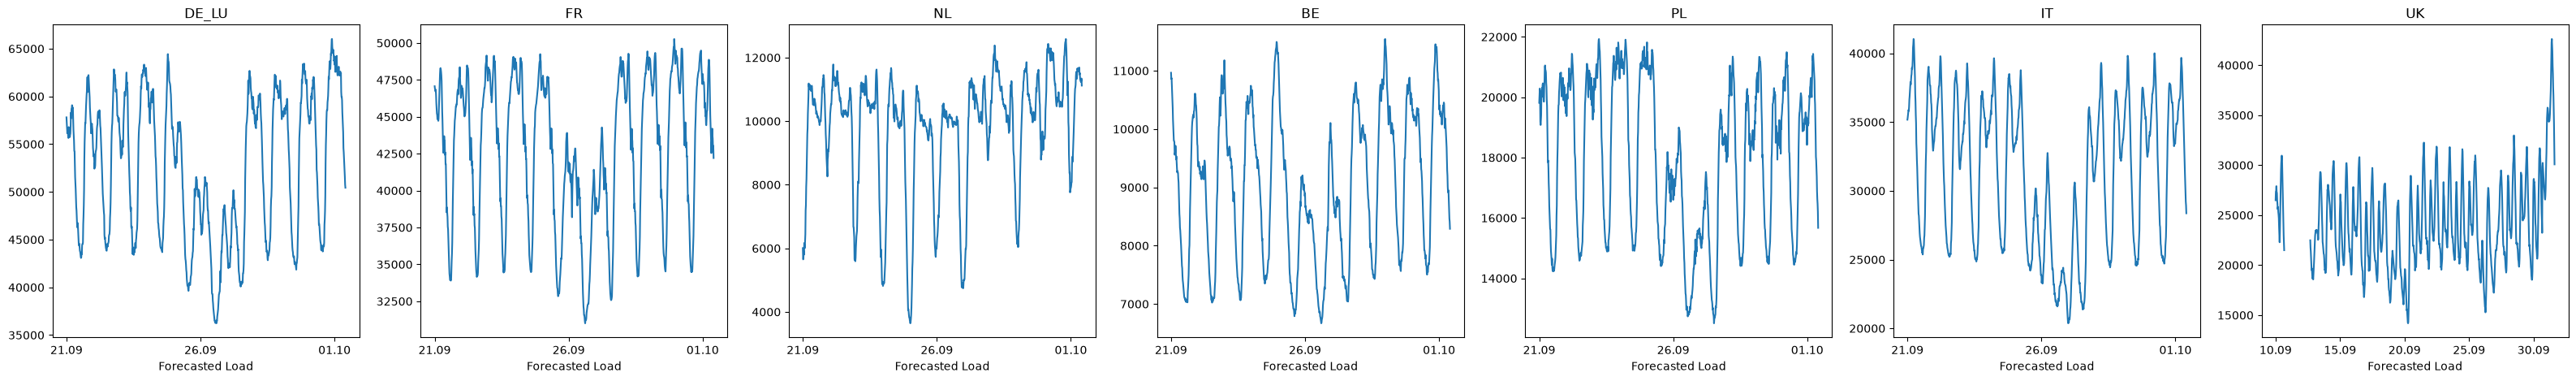

In [15]:
fig, ax = plt.subplots(nrows=1, ncols=7, figsize=(40, 5))
for i,country in enumerate(list(df_load_europe["country"].unique())):
    data = df_load_europe[df_load_europe["country"] == country].tail(1000)
    ax[i].plot(data["data"] , data["Actual Load"]) 
    ax[i].set_xticks(pd.date_range(data["data"].min(), data["data"].max(), freq="5D"))
    ax[i].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    ax[i].set_xlabel("Forecasted Load")
    ax[i].set_title(country)
    print(country)
plt.show()

Данные за **2024 год**. ВВП указан в текущих долларах США.

| Страна / территория | Площадь, тыс. км² | Население, млн человек | ВВП, млрд долларов |
|---|---:|---:|---:|
| Германия + Люксембург | 360,3 | 84,2 | 4 779 |
| Франция | 606,4 | 68,6 | 3 160 |
| Италия | 302,1 | 59,0 | 2 381 |
| Англия | ≈130,3 | 58,6 | ≈3 160 |
| Польша | 313,9 | 36,6 | 918 |
| Нидерланды | 41,5 | 18,0 | 1 215 |
| Бельгия | 30,7 | 11,9 | 671 |


- Тут все показатели по Германии и Люксембургу сложены , так как даты по энергетике у нас идут на обе страны вместе .+ Французский территории тут 



По графикам видно , что среднее потребление стоит в таким порядке :

1) Германия

2) Франция 

3) Италия

4) Англия

5) Польша 

6) Нидерланды

7) Бельгия 

Тут можно найти явную закономерность в населении.+ например интересный факт, что скорее всего , хотя у нас и получилось , что страны отранжировались по населению,однако например у Италии, у которой население примерно равено с Англией , потребление примерно в полтора раза выше , скорее всего это связано с терриориальным фактором, глобально.Тут вообще я думал, что получится какая-то зависимость в том , числе и на ВВП завязаная , тогда бы можно было сказать , что возможно экономические новости были бы полезны (можно было бы предположить), но пока тяжело это сказать, но вот например будет интересно исселдовать , какая будет переносимость данных у спортивных событий, так как спорт события и их потребленеи энергии явно зависит от населения.Тот же ЧЕ по футболу проводили в нескольких странах Евпропы в 21 году , интересно будет посомтреть что там да как 

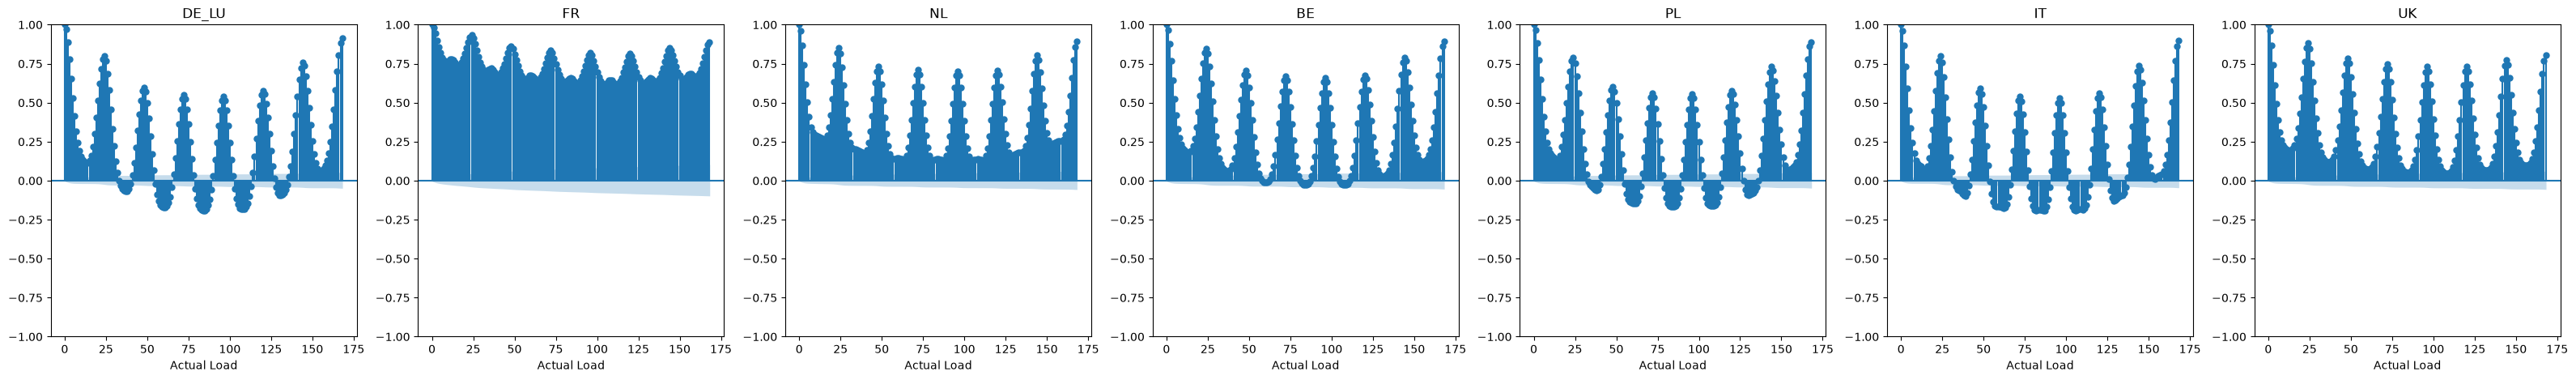

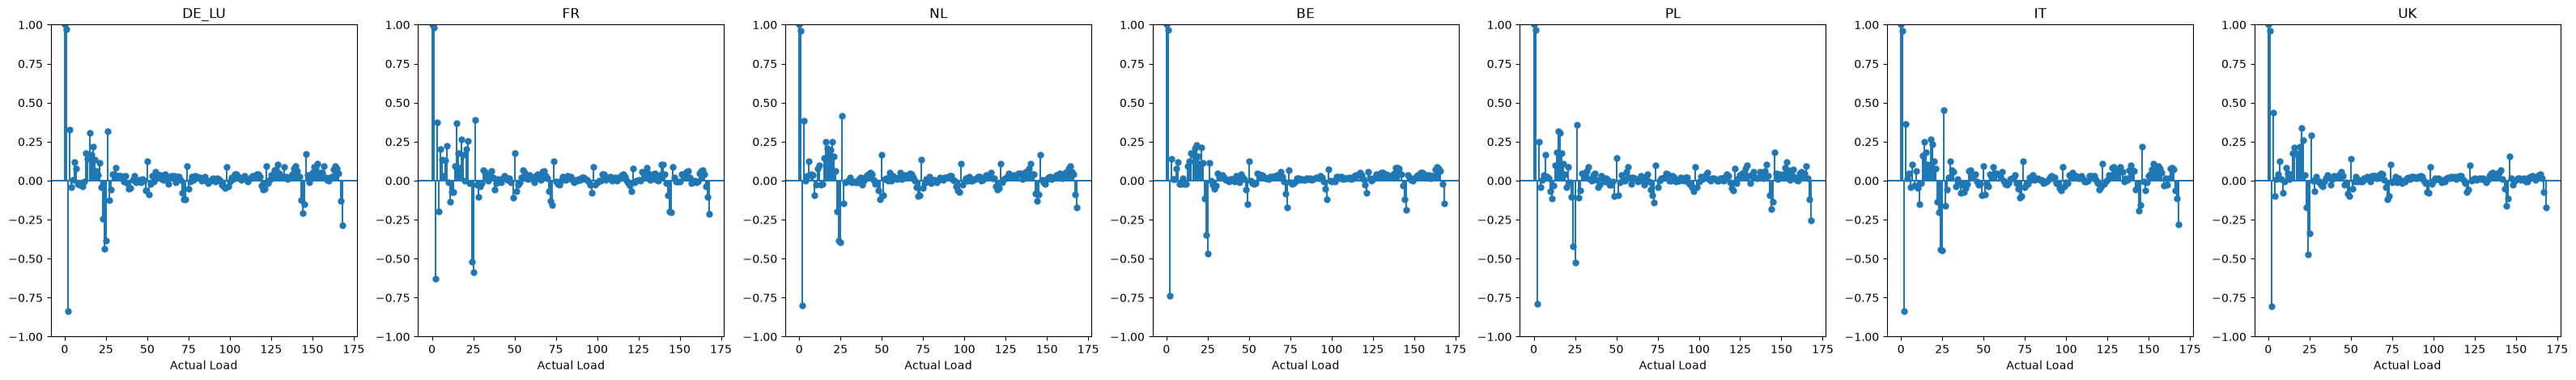

In [16]:
df_load_europe_hours = pd.DataFrame()
for country in list(df_load_europe["country"].unique()):
    mask = df_load_europe["country"] == country
    df_load_europe_1 = df_load_europe[mask][["data","Actual Load"]].set_index("data").resample("1h").mean()
    df_load_europe_1["country"] = country
    df_load_europe_hours = pd.concat([df_load_europe_hours , df_load_europe_1])
for country in list(df_load_europe_hours["country"].unique()):
    mask = (df_load_europe_hours["country"] == country)
    df_load_europe_hours.loc[mask] = df_load_europe_hours.loc[mask].ffill()
fig, ax = plt.subplots(nrows=1, ncols=7, figsize=(40, 5))
for i,country in enumerate(list(df_load_europe_hours["country"].unique())):
    data = df_load_europe_hours[df_load_europe_hours["country"] == country]["Actual Load"]
    plot_acf(data, lags=168, ax=ax[i])
    
    ax[i].set_xlabel("Actual Load")
    ax[i].set_title(country)
    
fig, ax = plt.subplots(nrows=1, ncols=7, figsize=(40, 5))
for i,country in enumerate(list(df_load_europe_hours["country"].unique())):
    data = df_load_europe_hours[df_load_europe_hours["country"] == country]["Actual Load"]
    plot_pacf(data, lags=168, ax=ax[i], method="ywm")
    ax[i].set_xlabel("Actual Load")
    ax[i].set_title(country)
    
    

In [ ]:
df_forecast_europe_hours = pd.DataFrame()
for country in list(df_forecast_europe["country"].unique()):
    mask =df_forecast_europe["country"] == country
    df_forecast_europe_1 =df_forecast_europe[mask][["data","Forecasted Load"]].set_index("data").resample("1h").mean()
    df_forecast_europe_1["country"] =country
    df_forecast_europe_hours =pd.concat([df_forecast_europe_hours ,df_forecast_europe_1])
for country in list(df_forecast_europe_hours["country"].unique()):
    mask =(df_forecast_europe_hours["country"] ==country)
    df_forecast_europe_hours.loc[mask] =df_forecast_europe_hours.loc[mask].ffill()

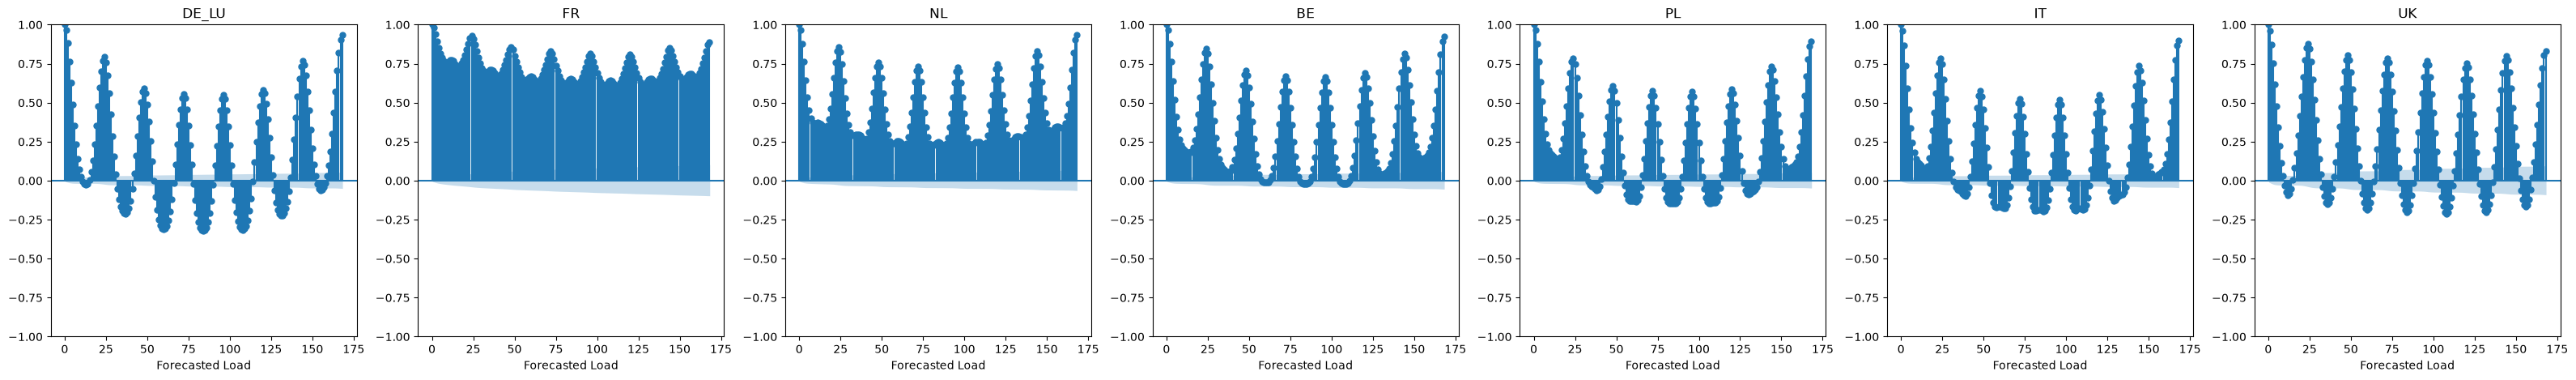

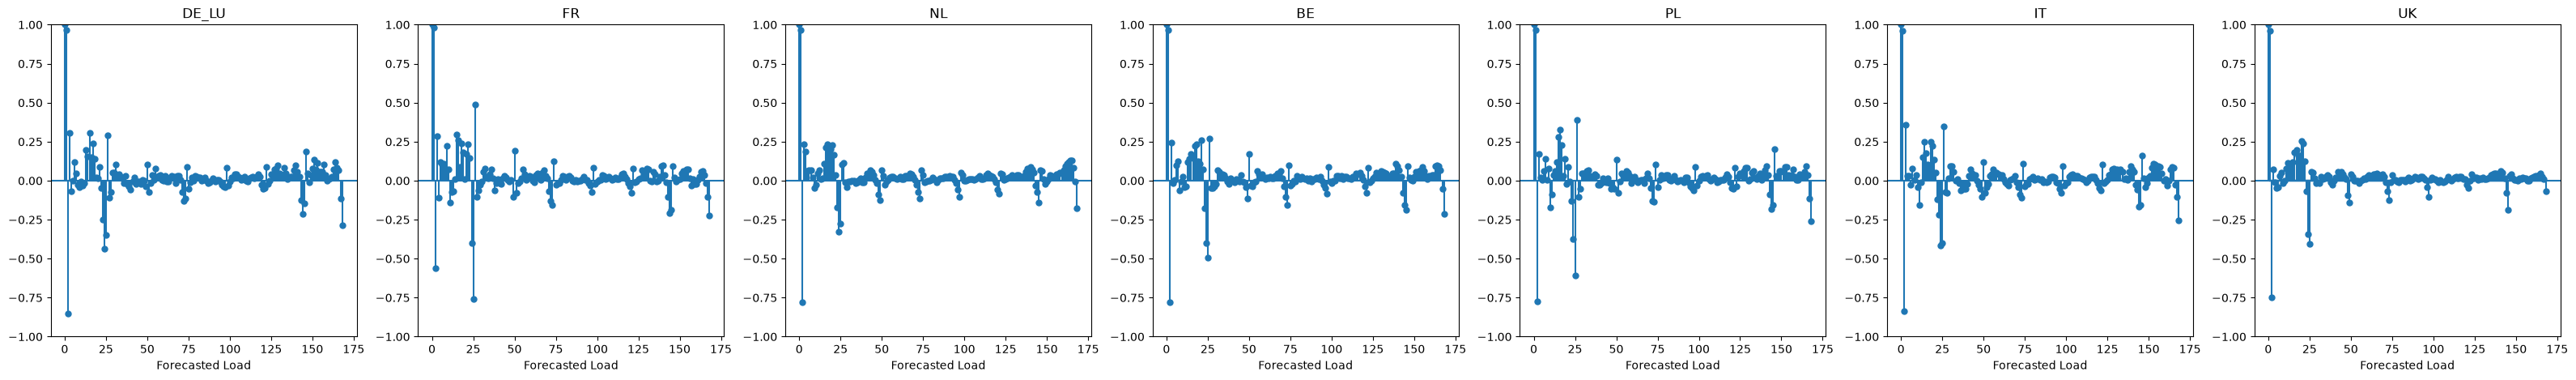

In [ ]:
fig,ax =plt.subplots(nrows=1, ncols=7, figsize=(40, 5))
for i,country in enumerate(list(df_forecast_europe_hours["country"].unique())):
    data =df_forecast_europe_hours[df_forecast_europe_hours["country"]==country]["Forecasted Load"]
    plot_acf(data,lags=168,ax=ax[i])
    ax[i].set_xlabel("Forecasted Load")
    ax[i].set_title(country)
    
fig,ax=plt.subplots(nrows=1,ncols=7,figsize=(40, 5))
for i,country in enumerate(list(df_forecast_europe_hours["country"].unique())):
    data=df_forecast_europe_hours[df_forecast_europe_hours["country"]==country]["Forecasted Load"]
    plot_pacf(data,lags=168,ax=ax[i], method="ywm")
    ax[i].set_xlabel("Forecasted Load")
    ax[i].set_title(country)
    
    

1) ACF у всех стран видна сильная суточная сезонность, очевидные сильные пики дневные.Пик на 168 лаге очеивдно говорит и о недельной сезонности
2) PACF даже после очистки от послеодовательной зависимости, все еще остаются междневные зависимови в районе 24 часов

Во Франции ACF остается высоким почти всегд.Скорее всего это связано со структурой генерации.Атомные электростанции генерируют элетричество непрерывно и в примерно равных количествам в любое время суток, и это генерацию куда-то надо девать, так как постоянно уменьшать/увеличивать генерацию в реакторах небезопасно.Это лишь предположение пока.


ACF: у всех стран видна сильная связь с предыдущими значениями. Пики примерно через каждые 24 часа указывают на суточную сезонность, а высокий пик около 168 часов- также на недельную
PACF: наиболее заметны ближайшие лаги и некоторые лаги около суток. После учёта промежуточных значений связь с большинством дальних лагов значительно слабее

In [19]:
df_interchange_europe=df_export_europe[["country","data","sum"]].merge(df_import_europe[["country","data","sum"]],
    on=["country","data"],how="outer",suffixes=("_export", "_import"),validate="one_to_one")
df_interchange_europe["total_interchange"]= (df_interchange_europe["sum_export"]-df_interchange_europe["sum_import"])

# посчитали так обмен , так как в США именно так они считали interchange

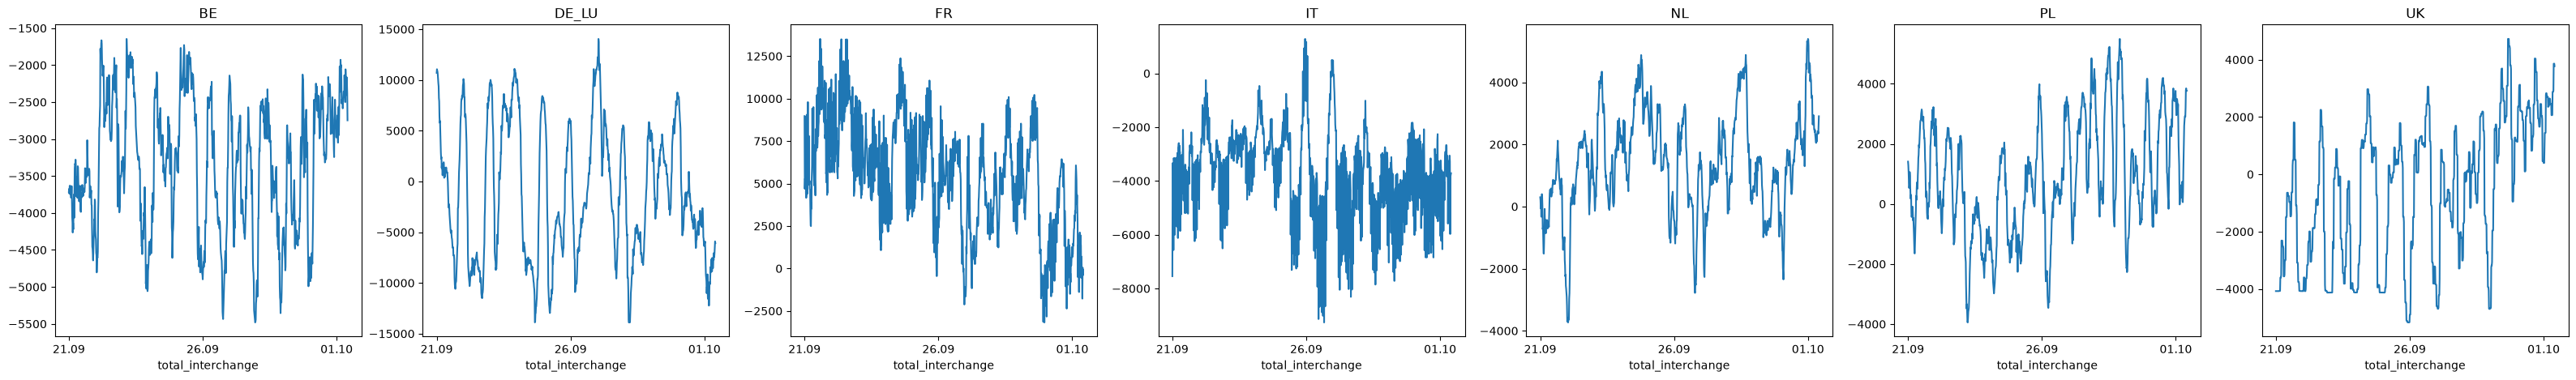

In [20]:
fig, ax = plt.subplots(nrows=1, ncols=7, figsize=(40, 5))
for i,country in enumerate(list(df_interchange_europe["country"].unique())):
    data = df_interchange_europe[df_interchange_europe["country"] == country].tail(1000)
    ax[i].plot(data["data"] , data["total_interchange"]) 
    ax[i].set_xticks(pd.date_range(data["data"].min(), data["data"].max(), freq="5D"))
    ax[i].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    ax[i].set_xlabel("total_interchange")
    ax[i].set_title(country)
plt.show()

In [21]:
df_interchange_europe_hours = pd.DataFrame()
for country in list(df_interchange_europe["country"].unique()):
    mask = df_interchange_europe["country"] == country
    df_interchange_europe_1 = df_interchange_europe[mask][["data","total_interchange"]].set_index("data").resample("1h").mean()
    df_interchange_europe_1["country"] = country
    df_interchange_europe_hours = pd.concat([df_interchange_europe_hours , df_interchange_europe_1])

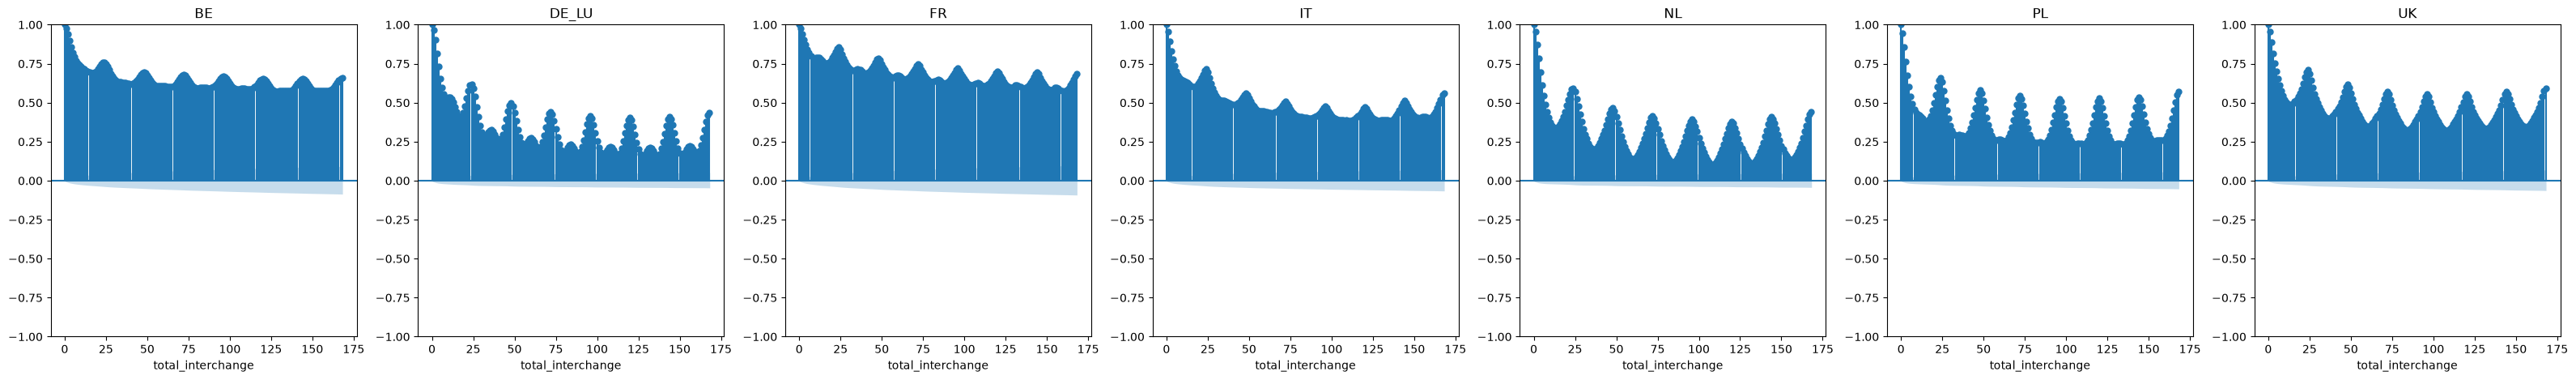

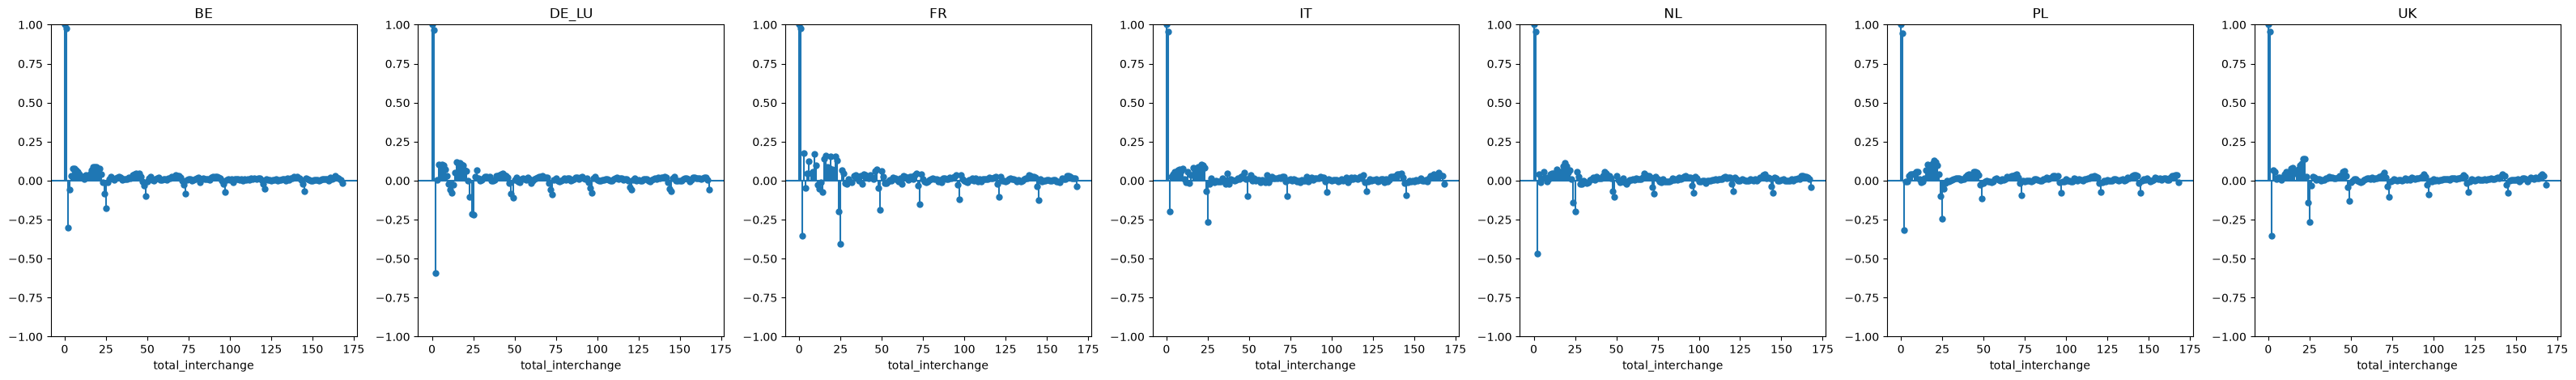

In [22]:
fig, ax = plt.subplots(nrows=1, ncols=7, figsize=(40, 5))
for i,country in enumerate(list(df_interchange_europe_hours["country"].unique())):
    data = df_interchange_europe_hours[df_interchange_europe_hours["country"] == country]["total_interchange"]
    plot_acf(data, lags=168, ax=ax[i])
    
    ax[i].set_xlabel("total_interchange")
    ax[i].set_title(country)
    
fig, ax = plt.subplots(nrows=1, ncols=7, figsize=(40, 5))
for i,country in enumerate(list(df_interchange_europe_hours["country"].unique())):
    data = df_interchange_europe_hours[df_interchange_europe_hours["country"] == country]["total_interchange"]
    plot_pacf(data, lags=168, ax=ax[i], method="ywm")
    ax[i].set_xlabel("total_interchange")
    ax[i].set_title(country)
    
    

1) Тут по ACF видно , что все данные очень сильно зависят от свои предыдущих значений 

2) Но по PACF видно , что полноценная связь с отдельными дальними лагами (не через связь с краткосрочными лагами) есть только у отдельных лагов, а именно дневными .То есть сильная дневная сезонность виднеется на графике 

По этим графикам также видно , что нет стран , являющихся исключительно экспортерами или импортерами энергии.

### США таргеты

Все графики по США построены на датах примерно с 1 октября

In [23]:
df_forecast_USA["period"] = pd.to_datetime(df_forecast_USA["period"])
df_demand_USA["period"] = pd.to_datetime(df_demand_USA["period"])
df_netgen_USA["period"] = pd.to_datetime(df_netgen_USA["period"])
df_inter_USA["period"] = pd.to_datetime(df_inter_USA["period"])

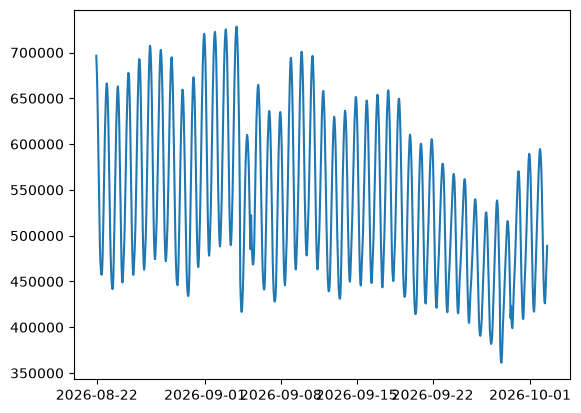

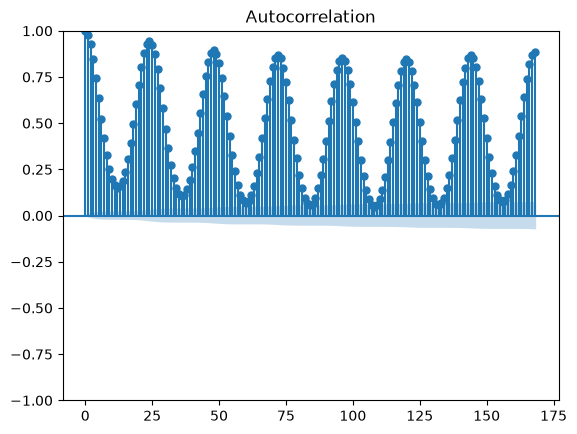

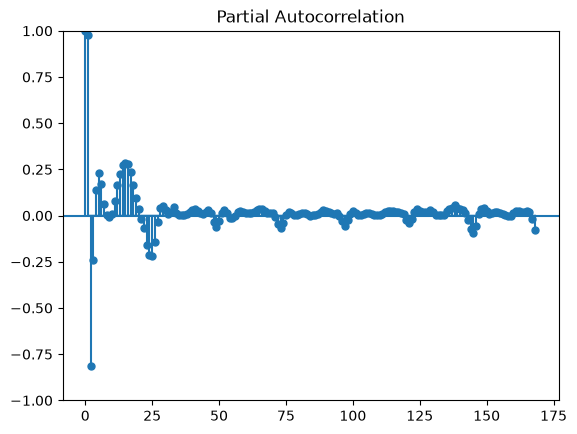

In [24]:

plt.plot(df_forecast_USA[df_forecast_USA["respondent"] == "US48"]["period"].tail(1000),df_forecast_USA[df_forecast_USA["respondent"] == "US48"]["value"].tail(1000)) # это полная инфа по США , по сути сумма по США
plot_acf(df_forecast_USA[df_forecast_USA["respondent"] == "US48"]["value"], lags=168)
plot_pacf(df_forecast_USA[df_forecast_USA["respondent"] == "US48"]["value"], lags=168)
plt.show()

Здесь картина по PACF достаточно сильно отличается от Евпропейской.Почти все лаги в пределах суток значимы по отдельности, даже без учета фактора предыдщих лагов на сам данный лаг(так как PACF) , в то время , как пики например в последующие 24 часовые периоды , сильно менее выраженные , чем в европейских данных.Тут я имею в виду, что после учёта промежуточных лагов прямые частные связи с более дальними лагами выглядят слабее

Тут предварительно можно сделать вывод, что реальный лаг в потребление в США сильно короче и менее цикличен , чем в Европе.В пределах тех дов интервалов , что едва видно.

Дальше я графики по США кроме обмена не будут смотреть,так как они очень сильно похожи,однако на графике потребления все таки более выражены чуть более дальние лаги на графике PACF, однако все еще наблюдается отличающаяся от Европейских стран картина


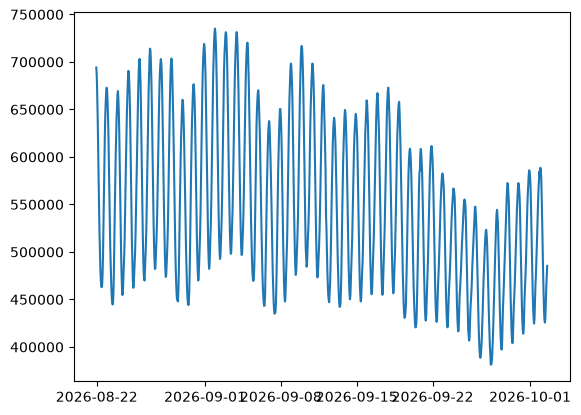

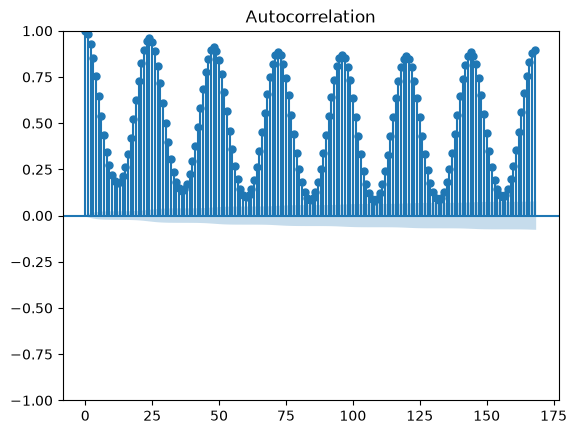

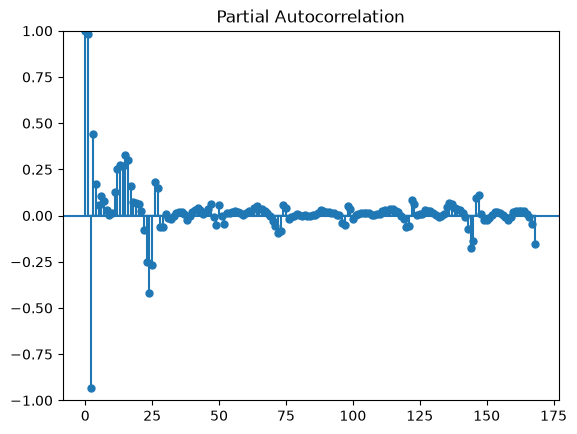

In [25]:
plt.plot(df_demand_USA[df_demand_USA["respondent"] == "US48"]["period"].tail(1000),df_demand_USA[df_demand_USA["respondent"] == "US48"]["value"].tail(1000))
plot_acf(df_demand_USA[df_demand_USA["respondent"] == "US48"]["value"], lags=168)
plot_pacf(df_demand_USA[df_demand_USA["respondent"] == "US48"]["value"], lags=168)
plt.show()

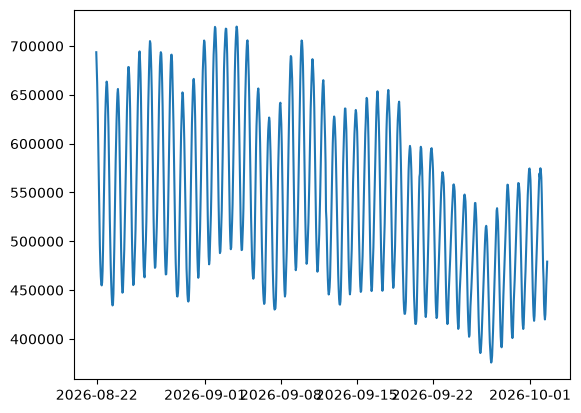

In [26]:
plt.plot(df_netgen_USA[df_netgen_USA["respondent"] == "US48"]["period"].tail(1000),df_netgen_USA[df_netgen_USA["respondent"] == "US48"]["value"].tail(1000))

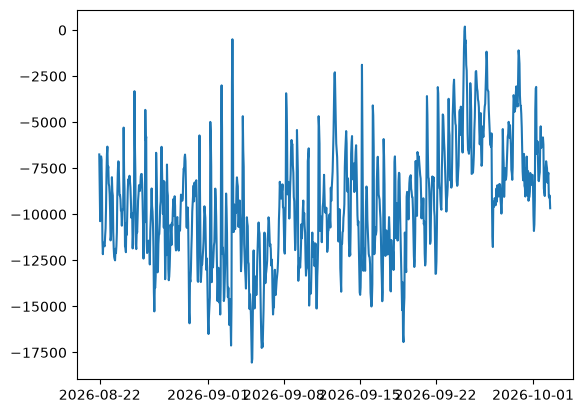

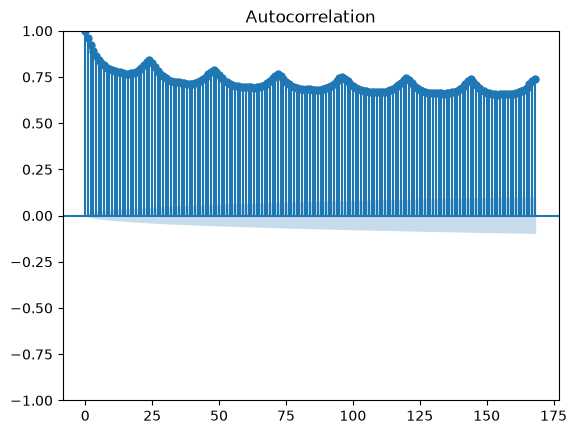

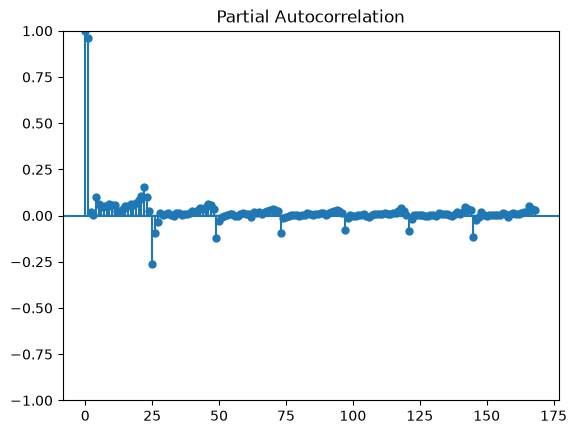

In [27]:
df_inter_USA
plt.plot(df_inter_USA[df_inter_USA["respondent"] == "US48"]["period"].tail(1000),df_inter_USA[df_inter_USA["respondent"] == "US48"]["value"].tail(1000))
plot_acf(df_inter_USA[df_inter_USA["respondent"] == "US48"]["value"], lags=168)
plot_pacf(df_inter_USA[df_inter_USA["respondent"] == "US48"]["value"], lags=168)
plt.show()

Тут видно хорошо, что по США у нас не только баланс между фирмами, но и между Канадой и Мексикой в том числе + что США почти чистый импортер энергии(скорее всего из-за дешевизны)

Остальные данные сильно сезонные 

По PACF тут уже картина сильно более похожая на европейские данные.

### Сезонный анализ и статистики всякие

In [28]:
eda_series={'Нагрузка':(df_load_europe_hours,'Actual Load'),'Прогноз нагрузки':(df_forecast_europe_hours,'Forecasted Load'),'Обмен: экспорт − импорт':(df_interchange_europe_hours,'total_interchange'),}
statistics=[]
largest_changes=[]

In [ ]:
for label,(frame, value) in eda_series.items():
    for country, part in frame.groupby('country', sort=True):
        s=part[value].sort_index()
        valid=s.dropna()
        stats={'тип ряда':label,'country':country,'строк':len(s),'среднее':valid.mean(),'медиана': valid.median(), 'мин': valid.min(), 'топ 1 процент верхних значений с ':valid.quantile(.99),'максимум': valid.max(),'доля отрицательных': (valid < 0).mean() if len(valid) else np.nan}
                         #доля отрицательных чтобы понять в основном страна экспортер или импортрерx
        statistics.append(stats)
        delta=s.diff().where(s.index.to_series().diff().eq(pd.Timedelta('1h')).to_numpy())
        largest=delta.abs().nlargest(3).index
        for when in largest:
            largest_changes.append({'ряд':label,'страна':country,'время': when,'изменение за час': delta.loc[when], 'значение': s.loc[when]})
eda_statistics=pd.DataFrame(statistics)
eda_largest_changes=pd.DataFrame(largest_changes)
display(eda_statistics)

,тип ряда,country,строк,среднее,медиана,мин,топ 1 процент верхних значений с,максимум,доля отрицательных
0,Нагрузка,BE,67943,9334.321327,9309.330000,5930.182500,12439.204250,13616.182500,0.000000
1,Нагрузка,DE_LU,67943,55125.296937,55002.852500,31278.372500,75240.011520,82115.670000,0.000000
2,Нагрузка,FR,67943,50533.608700,48649.000000,28744.000000,78980.560000,89958.900000,0.000000
3,Нагрузка,IT,67943,32267.397075,31820.000000,15334.000000,47450.870000,53824.000000,0.000000
4,Нагрузка,NL,67943,12612.660435,12423.102500,3696.954250,17853.586295,20499.267750,0.000000
5,Нагрузка,PL,67943,18982.910361,19004.885750,10595.800250,25834.341900,28303.880000,0.000000
6,Нагрузка,UK,67942,26935.024528,25987.500000,12726.000000,42632.885000,47310.500000,0.000000
7,Прогноз нагрузки,BE,67943,9353.199871,9321.082500,6091.437500,12310.400850,13629.467500,0.000000
8,Прогноз нагрузки,DE_LU,67943,54594.385240,54452.122707,30893.055000,72088.623800,78154.370000,0.000000
9,Прогноз нагрузки,FR,67943,50583.887143,48700.000000,27650.000000,79264.500000,89563.750000,0.000000


Можно посмотреть, в целом каких то полезных новых инсайтов кажется , что тут нет

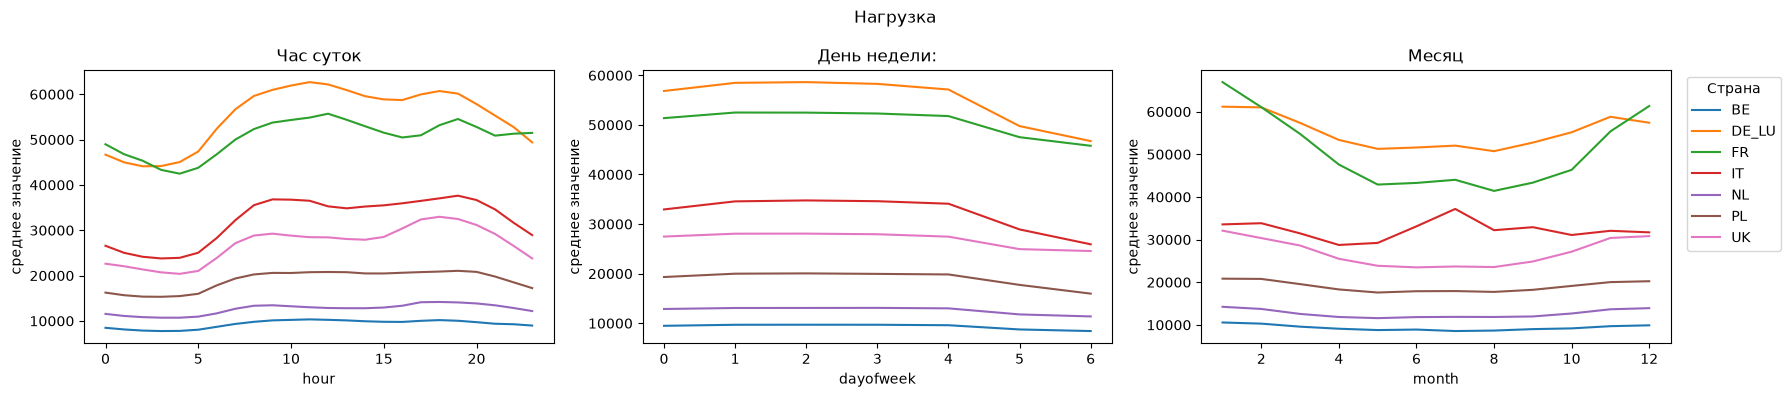

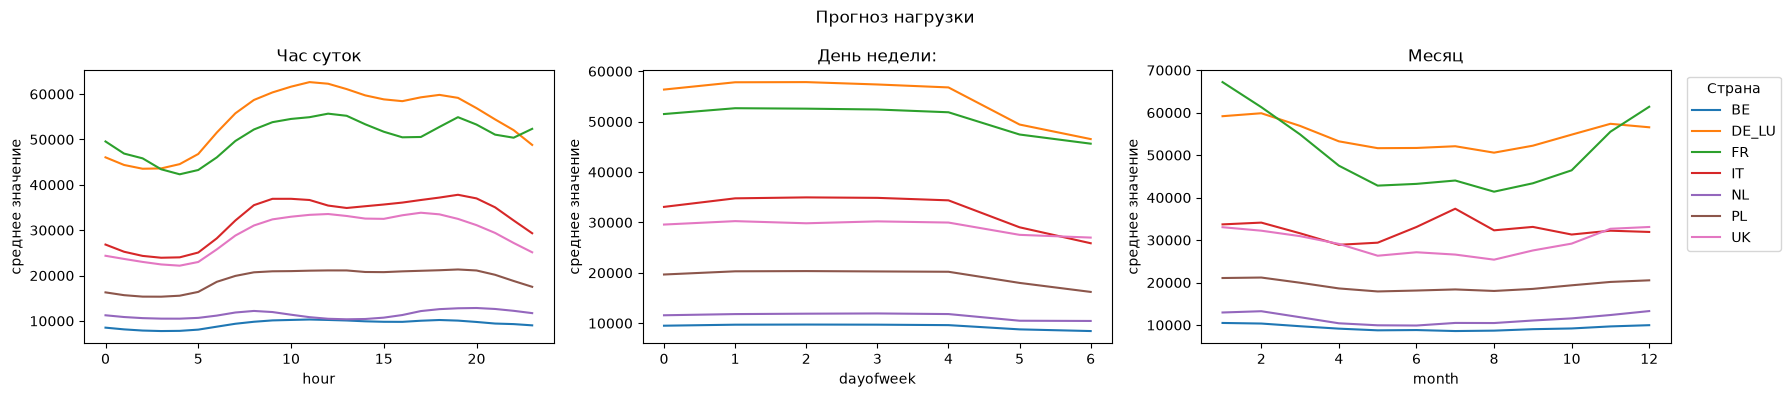

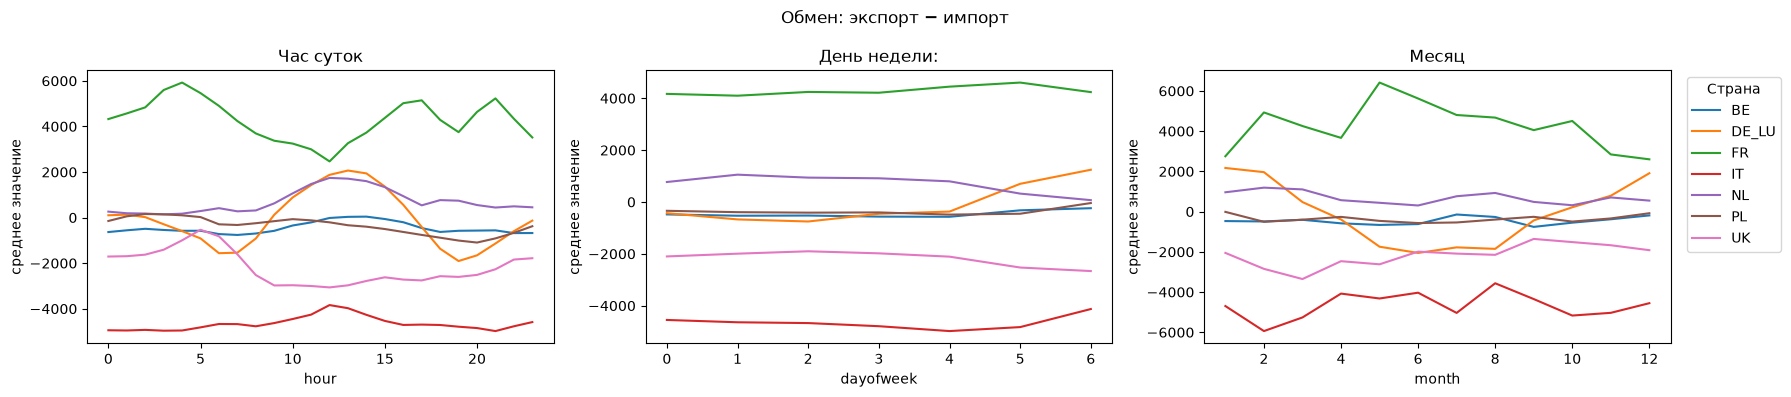

In [64]:
TIMEZONES = {"FR":"Europe/Paris","DE_LU":"Europe/Berlin","NL": "Europe/Amsterdam","BE":"Europe/Brussels","PL":"Europe/Warsaw","IT":"Europe/Rome","UK":"Europe/London","GB":"Europe/London"}
eda_profiles={}
for name in eda_series:
    frame,value=eda_series[name]
    parts=[]
    for country in sorted(list(frame["country"].unique())):
        mask=frame["country"] ==country
        data=frame.loc[mask, ["country",value]].copy()
        data=data.rename(columns={value:"value"})
        local=data.index.tz_convert(TIMEZONES.get(country,"UTC"))
        data["hour"]=local.hour
        data["dayofweek"]=local.dayofweek
        data["month"]=local.month
        data["year"]=local.year
        parts.append(data)
    eda_profiles[name]=pd.concat(parts,ignore_index=True)
    fig,ax=plt.subplots(nrows=1,ncols=3,figsize=(18, 4))
    titles = ["Час суток", "День недели:","Месяц"]#тут получается что 0 это понедельник 
    for i, key in enumerate(["hour", "dayofweek", "month"]):
        data=eda_profiles[name].groupby(["country",key])["value"].mean().unstack("country")
        data.plot(ax=ax[i], legend=False)
        ax[i].set_title(titles[i])
        ax[i].set_ylabel("среднее значение")
    ax[2].legend(title="Страна",bbox_to_anchor=(1.02,1),loc="upper left")
    fig.suptitle(name)
    fig.tight_layout()
    plt.show()

1) Время суток 
    * Тут у всех стран наблюдается явный внутресуточный профиль(в целом ожидаемый) Ближе к 5 утра потребление находится на нуле(большая часть страны спит) , а в районе 19 часов пик, вся страна пришла домой и включила чайники с телевизорами.Тут мы говорили про потребление.

    * В экспорте импорте , таких явных закономерностей не находится и в целом тут ряды разнозненые по структуре в зависимости от страны .

2) День недели
    * Тут интересно в целом .Раньше Роберт уже подбивал , что во многом потребление зависит от населения .Но тут получается чуть другой профиль.Если бы потребление зависело исключительно от населения, скорее всего в выходные бы оно росло,так как люди отдыхают пьют чай и смотрят телевизоры .Однако происходит падение, скорее всего связанное уже с промышленной/в целом трудовой деательность.По выходным люди больше смотрят телевиоз в течение дня и больше выпивают чая , но предприятия не льют алюминий и не строят отчеты в excel по выходным .ТО есть все таки в том числе потребление сильно зависит от трудовой активности внутри страны , и например новости связаные с трудовой активностью, могли бы положительно влиять на долгосрочные прогнозы

    * По экспорту/импорту ситуация в рабочии дни стабильная.В выходные же картинка также как и в внутресуточных калебаниях, сильно зависит по структуре от страны.

3) Месячный профиль 
    * По месяцам тоже есть прикольные наблюдения.Большинство стран зимой тратят больше энергии-это интуитивно понятно, обогреваться нужно всем.Однако в Италии в среднем летом траты больше , чем зимой.Скорее всего это связано с тем, что летом в италии тратят на кондиционирование из-а сумашедшей жары больше,чем тратят зимой , так как климат позволяет не прям сильно включать отопление

    * по экспорту импорту такая же картина как и раньше, явных зависимостей между странами нет 
    

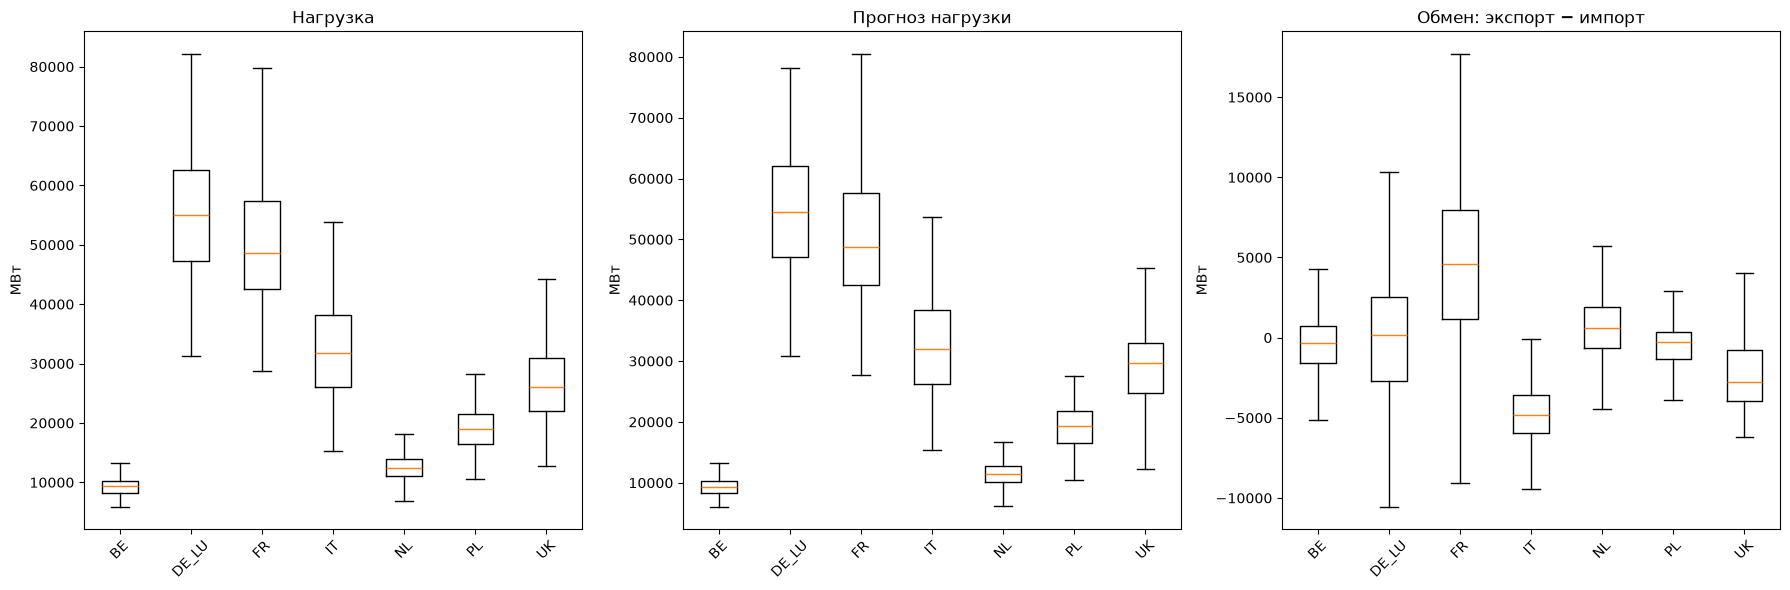

In [60]:
fig,axes= plt.subplots(1,len(eda_series),figsize=(18, 6))
for ax,(name,(frame, value)) in zip(axes,eda_series.items()):
    countries=sorted(frame['country'].unique())
    samples=[frame.loc[frame.country==c,value].dropna().to_numpy() for c in countries]
    ax.boxplot(samples,tick_labels=countries,showfliers=False)
    ax.set_title(name)
    ax.set_ylabel('МВт')
    ax.tick_params(axis='x',rotation=45)
fig.tight_layout()
plt.show()

Хотя тут и в целом похожи профили между прогонозом и реальной нагрузкой, реальную точность надо дополнительно смотреть, так как распределение может быть похоже , но абсолютные значения прогнозов могут  быть при этом не близки

In [37]:
generation_columns = [c for c in df_gen_europe.columns if 'Actual Aggregated' in str(c)]
gen=df_gen_europe[['country','data',*generation_columns]]
gen['data']=pd.to_datetime(gen['data'], format='mixed', utc=True, errors='raise')
df_gen_europe_hours=(gen.groupby(['country',pd.Grouper(key='data',freq='1h')])[generation_columns].mean().reset_index())
eda_generation_means=df_gen_europe_hours.groupby('country')[generation_columns].mean().T
display(eda_generation_means)



country,BE,DE_LU,FR,IT,NL,PL,UK
"('Biomass', 'Actual Aggregated')",298.424689,4308.540326,353.518087,606.345830,45.152975,249.936525,1949.573232
"('Fossil Brown coal/Lignite', 'Actual Aggregated')",0.000000,9606.542278,0.000000,0.000000,0.000000,4038.647614,0.000000
"('Fossil Coal-derived gas', 'Actual Aggregated')",0.000000,273.916740,0.000000,573.214816,0.000000,87.414420,0.000000
"('Fossil Gas', 'Actual Aggregated')",2305.790582,6464.273160,3252.550507,12194.579673,4364.789512,1609.517439,10196.413448
"('Fossil Hard coal', 'Actual Aggregated')",0.000000,4644.151165,178.966977,1238.798647,1681.277230,7622.903852,336.684437
"('Fossil Oil', 'Actual Aggregated')",38.420303,367.113532,165.624628,148.923988,0.000000,216.491756,0.000758
"('Geothermal', 'Actual Aggregated')",0.000000,23.127196,0.000000,618.345466,0.000000,0.000000,0.000000
"('Hydro Pumped Storage', 'Actual Aggregated')",121.359746,1118.516401,673.797837,431.365060,0.000000,133.923828,196.264108
"('Hydro Run-of-river and pondage', 'Actual Aggregated')",32.814495,1537.990996,4458.154243,3585.697986,0.000000,160.021889,384.208796
"('Hydro Water Reservoir', 'Actual Aggregated')",0.000000,182.913984,1639.911086,615.461928,0.000000,27.719801,0.000000


* Страны скорее всего будут сильно зависеть от погодных условий , так как например Франция и Германия достаточно большую долю генерируют способами сильно зависищями от погодных условий

*  Больше выводов наверно особо не сделаешь, просто может быть будет полезно потом уже при работе с моделью

,hours,bias,mae,correlation
country,,,,
BE,67943,18.878544,259.410720,0.966262
DE_LU,67943,-530.911698,2101.674457,0.963273
FR,67943,50.278442,944.615852,0.993632
IT,67943,159.420753,692.881000,0.991912
NL,67943,-1191.687726,1651.527762,0.607541
PL,67943,300.498225,483.850272,0.986337
UK,28438,3352.094069,4430.605489,0.671394


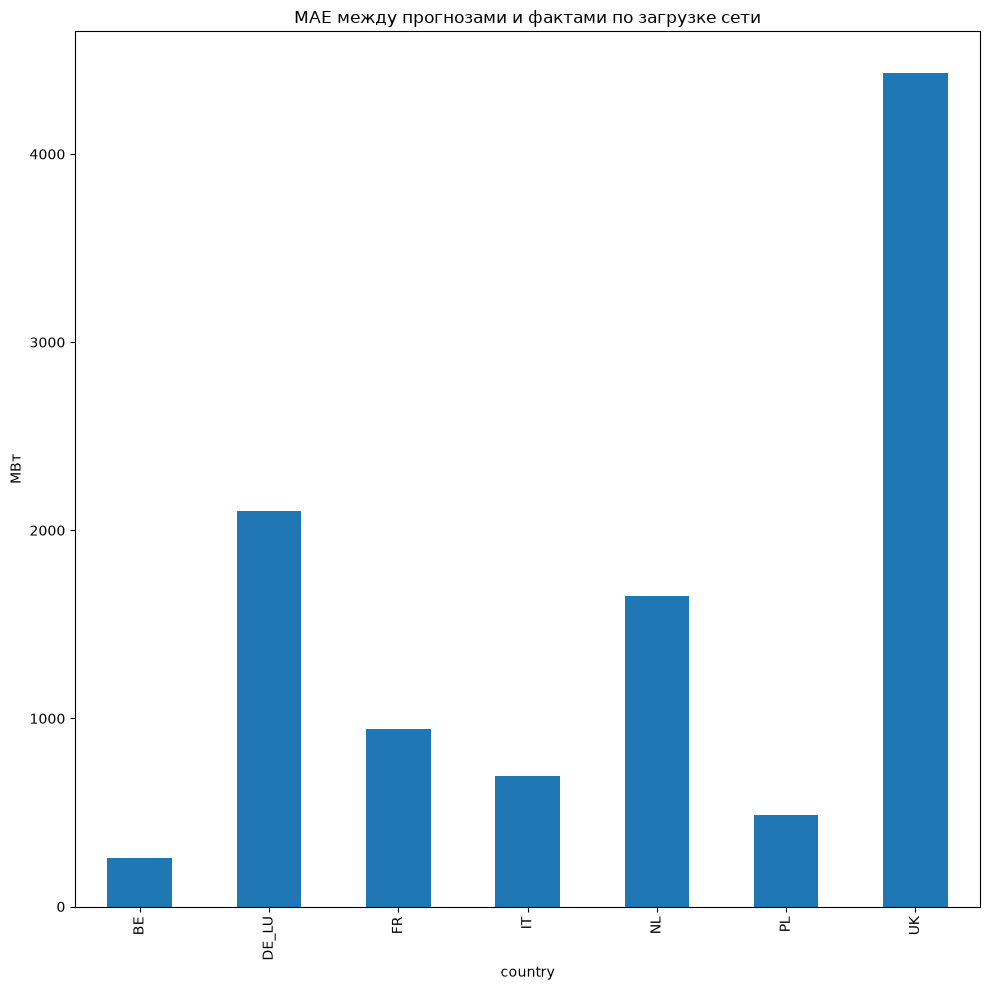

In [65]:
eda_load_forecast=df_load_europe_hours.reset_index().merge(df_forecast_europe_hours.reset_index(),on=["country","data"], how="inner")
eda_load_forecast=eda_load_forecast.dropna(subset=["Actual Load","Forecasted Load"])
eda_load_forecast["error"]=eda_load_forecast["Forecasted Load"]-eda_load_forecast["Actual Load"]
eda_load_forecast["abs_error"]=eda_load_forecast["error"].abs()
rows=[]
for country in sorted(eda_load_forecast["country"].unique()):
    mask=eda_load_forecast["country"] == country
    data= eda_load_forecast[mask]
    hours= len(data)
    bias= data["error"].mean()
    mae= data["abs_error"].mean()
    correlation=data["Actual Load"].corr(data["Forecasted Load"])
    rows.append([country,hours,bias,mae,correlation])
eda_forecast_quality=pd.DataFrame(rows,columns=["country","hours","bias","mae","correlation"]).set_index("country")
display(eda_forecast_quality)
fig,ax=plt.subplots(figsize=(10, 10))
eda_forecast_quality["mae"].plot.bar(ax=ax, title="MAE между прогнозами и фактами по загрузке сети")
ax.set_ylabel("МВт")
fig.tight_layout()
plt.show()

Франции скорее всего сильно легче предсказывать генерацию из-за того, что атомная энергетика работает.Роберт писал выше , что атомная энергетика работает очень стабильно и генерирует всегда примерно на одном уровне(в маленькой дисперсией) поэтому навернео потребление тоже более менее стабильное

По германии в абсолютных величинах большая ,но если смотреть относительно то это примерно 5 процентов ошибки в среднем , кстати что для таких рядов не самый качественный результат может быть , как мне кажется

In [67]:
baseline_rows=[]
stationarity =[]
for country in list(df_load_europe_hours["country"].unique()):
    mask =df_load_europe_hours["country"] ==country
    data =df_load_europe_hours.loc[mask,"Actual Load"].sort_index().asfreq("1h")
    for lag in (24, 168):
        error =(data-data.shift(lag)).iloc[int(len(data)*0.8):].dropna()
        baseline_rows.append([country,lag,len(error),error.abs().mean()])
    daily=data.resample("1D").agg(["mean", "count"])
    daily =daily["mean"].where(daily["count"] == 24)
    sample =max((part for _,part in daily.dropna().groupby(daily.isna().cumsum())),key=len).tail(1095)
    stationarity.append([country, len(sample), sample.index[0], sample.index[-1], adfuller(sample, autolag="AIC")[1],kpss(sample,regression="c",nlags="auto")[1]])
eda_baselines=pd.DataFrame(baseline_rows, columns=["country","лагг","пар","MAE мегавпт"])
eda_stationarity=pd.DataFrame(stationarity, columns=["country","days","start","end","ADF p","KPSS p"])
display(eda_baselines)
display(eda_stationarity)

C:\Users\Robert\AppData\Local\Temp\ipykernel_22656\3314136645.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stationarity.append([country, len(sample), sample.index[0], sample.index[-1], adfuller(sample, autolag="AIC")[1],kpss(sample,regression="c",nlags="auto")[1]])
C:\Users\Robert\AppData\Local\Temp\ipykernel_22656\3314136645.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stationarity.append([country, len(sample), sample.index[0], sample.index[-1], adfuller(sample, autolag="AIC")[1],kpss(sample,regression="c",nlags="auto")[1]])
C:\Users\Robert\A

,country,лагг,пар,MAE мегавпт
0,DE_LU,24,13589,3932.422053
1,DE_LU,168,13589,2723.010481
2,FR,24,13589,2431.624987
3,FR,168,13589,3139.140863
4,NL,24,13589,703.546695
5,NL,168,13589,637.525015
6,BE,24,13589,499.425992
7,BE,168,13589,445.938647
8,PL,24,13589,1335.521433
9,PL,168,13589,978.901048


,country,days,start,end,ADF p,KPSS p
0,DE_LU,1095,2023-10-02 00:00:00+00:00,2026-09-30 00:00:00+00:00,0.022543,0.100000
1,FR,1095,2023-10-02 00:00:00+00:00,2026-09-30 00:00:00+00:00,0.163581,0.100000
2,NL,1095,2023-10-02 00:00:00+00:00,2026-09-30 00:00:00+00:00,0.350950,0.100000
3,BE,1095,2023-10-02 00:00:00+00:00,2026-09-30 00:00:00+00:00,0.027731,0.100000
4,PL,1095,2023-10-02 00:00:00+00:00,2026-09-30 00:00:00+00:00,0.012025,0.010706
5,IT,1095,2023-10-02 00:00:00+00:00,2026-09-30 00:00:00+00:00,0.000222,0.100000
6,UK,1095,2023-10-02 00:00:00+00:00,2026-09-30 00:00:00+00:00,0.007072,0.033750


* Данные оценки по MAE , мы в целом можем считать чуть улучшенной версий наивного прогноза , и считать это например baselinом , но еще нужно будет посмотреть уже при составлении модели, как себя ведет классический наивный прогноз, но в целом кажется, что результаты в верхней табличе могли бы быть даже очень сильным baselinом

* По второй табличке мы видим согласованность несогласованость двух тестов на стационарность.Германи , Бельгия и Италия , скорее всего имеют стационарные ряды по потреблению, ведь оба теста согласованы.У остальных рядов таких сильных предпосылок для того, чтобы сказать что ряды стационарны нет(в смысле
 согласованость именно обоих тестов одновременно)

### Небольшой анализ по текстовым данным

In [41]:
project_root=Path(r"D:\research")
corpora ={"Энергетика":"all_countries_electricity_texts","Государствао":"all_countries_government_politics_texts","Новости": "all_countries_general_news_texts",
    "Погода":"all_countries_weather_texts"}
fields=["document_id","territory","source_id","source_kind","document_kind","title","word_count","published_at_utc","publication_date","snapshot_time_utc","date_method","availability_time_quality","language"]
# тут во многом приходится подстраиватся под названия, Роберт в сообщении вам писал ,что парсер делала нейронка , он вроде сам по себе неплохо отработал, только с файлами все таки приведтся повозится
eda_texts=pd.concat([pd.read_json(project_root/folder/"metadata.jsonl",lines=True,dtype=False,convert_dates=False).reindex(columns=fields).assign(корпус=corpus) for corpus, folder in corpora.items()], ignore_index=True)
eda_texts["country"]=eda_texts["territory"].replace({"UK": "GB"})
dates=eda_texts[["published_at_utc", "publication_date", "snapshot_time_utc"]]
eda_texts["basis"]=np.select([dates[col].notna() for col in dates], ["publication_time", "publication_date", "snapshot_time"], default="date_missing")
eda_texts["date"]=pd.to_datetime(dates.bfill(axis=1).iloc[:,0],format="mixed",utc=True)
eda_texts["month"] =eda_texts["date"].dt.strftime("%Y-%m")
eda_texts["word_count"] =pd.to_numeric(eda_texts["word_count"])
display(eda_texts.groupby("корпус").agg(texts=("document_id","size"),countries=("country", "nunique"),sources=("source_id","nunique"),without_month=("month",lambda x: x.isna().sum())))

,texts,countries,sources,without_month
корпус,,,,
Государствао,246752,8,28,0
Новости,111527,8,21,0
Погода,324622,8,41,0
Энергетика,53969,8,29,0


Более менее есть разнообразные источники, при условии , что у нас не так много стран.ПО 3/4 источника на каждый тип текстов есть вроде.

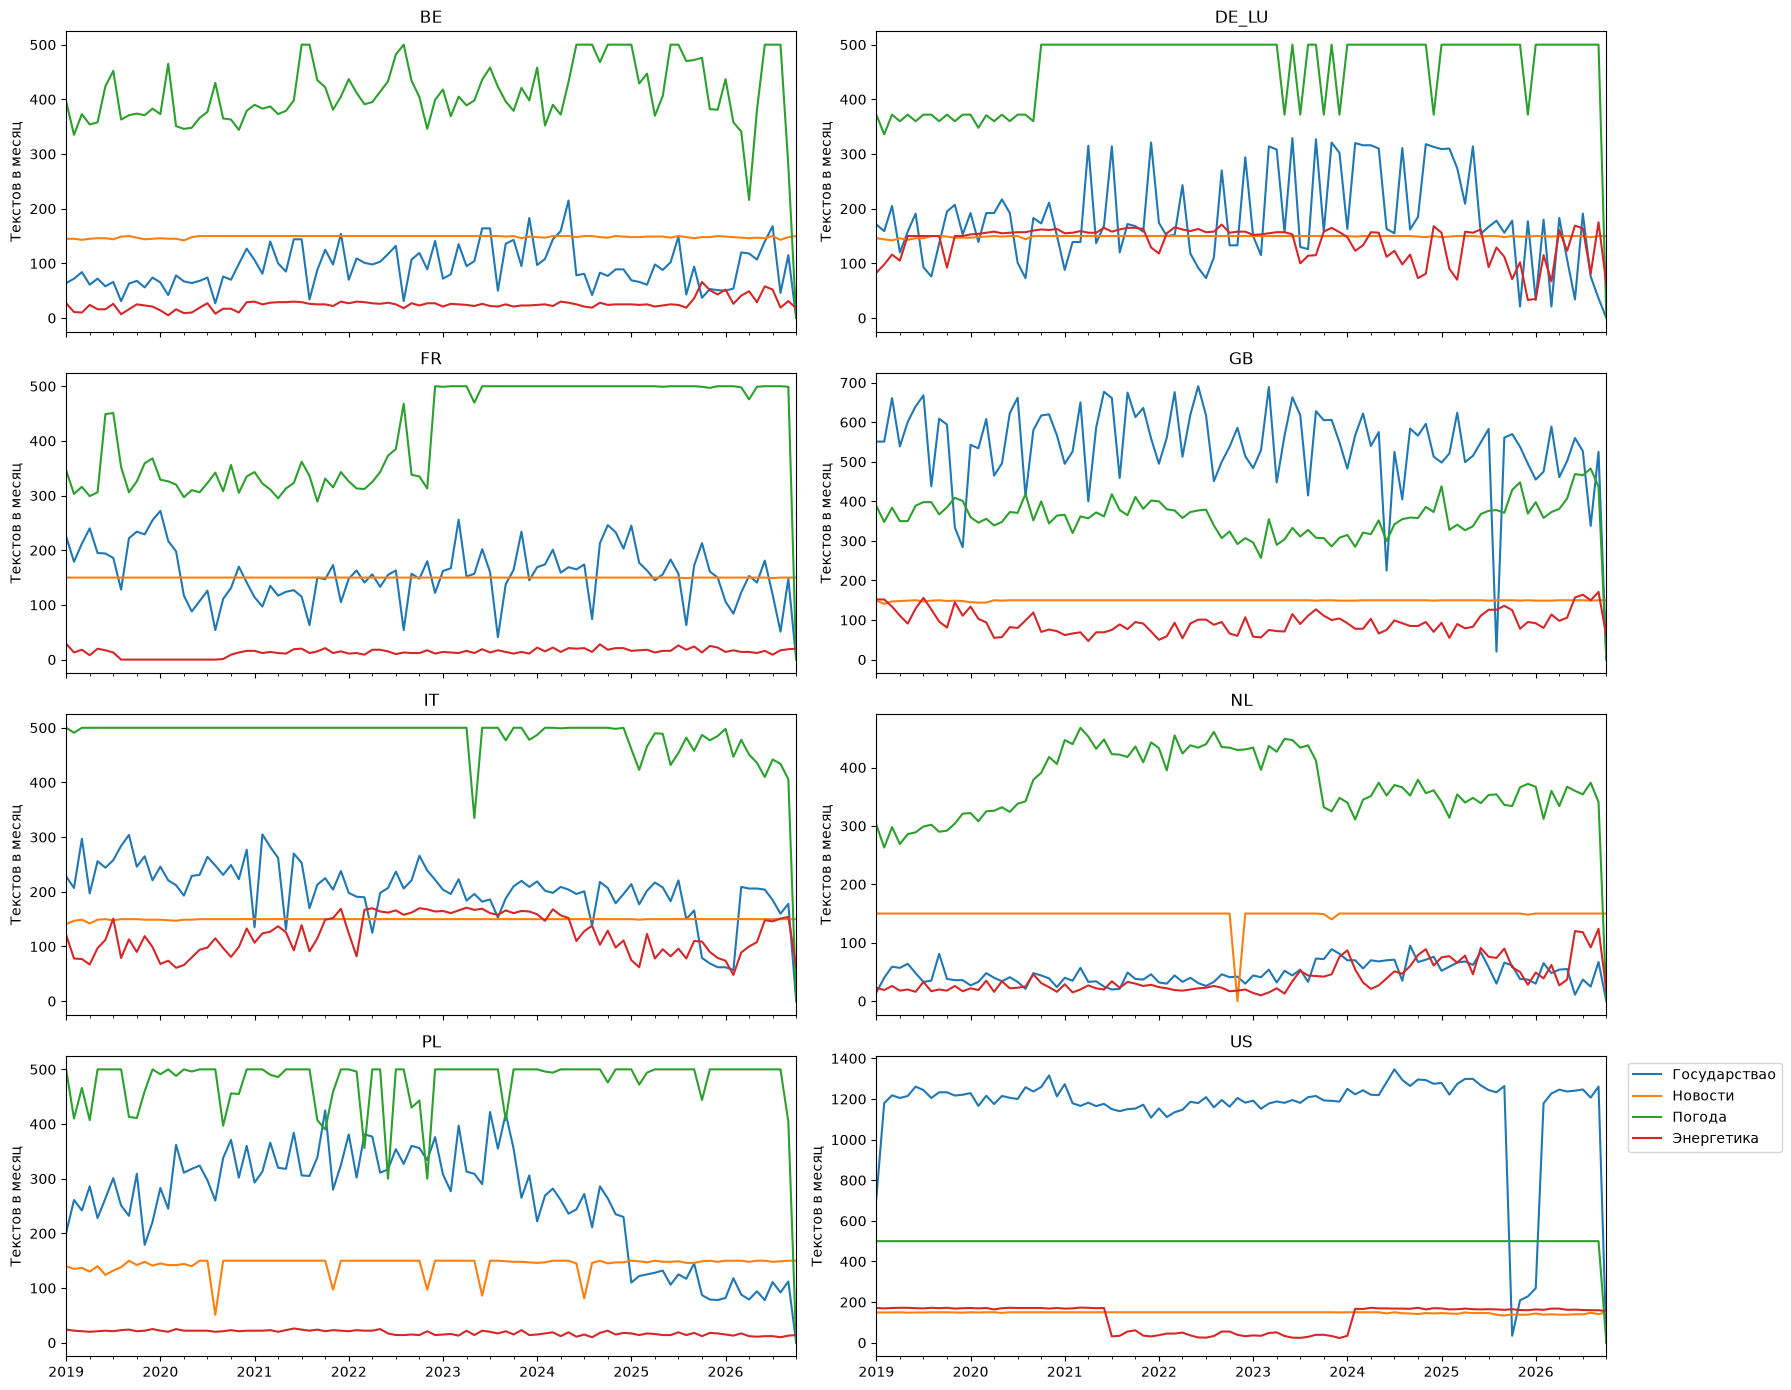

In [42]:
country_list=["BE","DE_LU","FR","GB","IT","NL","PL","US"]
first_month,last_month =eda_texts["month"].dropna().agg(["min", "max"])
month_list =pd.period_range(first_month,last_month,freq="M").astype(str)
fig,ax =plt.subplots(nrows=4,ncols=2,figsize=(18, 14),sharex=True)
for i, country in enumerate(country_list):
    mask =eda_texts["country"]==country
    data =eda_texts[mask].groupby(["month","корпус"]).size().unstack(fill_value=0)
    data=data.reindex(index=month_list,columns=sorted(corpora),fill_value=0)
    data.index=pd.to_datetime(data.index)
    data.plot(ax=ax.flat[i],legend=False)
    ax.flat[i].set_title(country)
    ax.flat[i].set_ylabel("Текстов в месяц")
ax.flat[-1].legend(bbox_to_anchor=(1.02,1),loc="upper left")
fig.tight_layout()
plt.show()

* Так как парсер писала нейронка , я просил каждый месяц отбирать более менее разные новости для каждого месяца каждой страны.Исследовать смещение в самих текстах еще предстоит, но мы старались ограничить например новости, так как скорее всего это может быть один из саымз информативных краткосрочных источников информации и что важно , с новостями нет большой проблемы с датированием, в отличие например от погоды , которые мы решили не ограничивать при скачивании, так как думаем , что многие тексты по погоде отсеятся из-за возможжных ликов.

* По погоде видно явное падение в 3 квартале 26 года.Там уже совсем все плохо было по текстам с погодой в этот период.Мы решили пока пропустить погоду в этот период, в будущем может доберем , если найдем новый полнцоенный источник.

* Также видно, что на США в плане текстов про государство и политику не было никаких ограничений , поэтому надо будет рандомно сэмплировать данные из текстов по государству США, иначе они будут занимать огромную долю во всех текстах по государству.В Бриатнии тоже сильно больше текстов с государством ,чем в среднем у остальных, поэтому тоже скорее всего придется сэкплировать

In [43]:
eda_text_summary=eda_texts.groupby(["country", "корпус"],dropna=False).agg(texts=("document_id", "size"),months=("month", "nunique"),
    first_month=("month", "min"),last_month=("month", "max"),median_words=("word_count", "median")).reset_index()
display(eda_text_summary)

,country,корпус,texts,months,first_month,last_month,median_words
0,BE,Государствао,8654,93,2019-01,2026-09,203.0
1,BE,Новости,13960,94,2019-01,2026-10,327.0
2,BE,Погода,38266,93,2019-01,2026-09,42.0
3,BE,Энергетика,2377,94,2019-01,2026-10,41.0
4,DE_LU,Государствао,17140,93,2019-01,2026-09,441.0
5,DE_LU,Новости,14028,94,2019-01,2026-10,495.0
6,DE_LU,Погода,42899,93,2019-01,2026-09,45.0
7,DE_LU,Энергетика,12914,94,2019-01,2026-10,38.0
8,FR,Государствао,14667,93,2019-01,2026-09,643.0
9,FR,Новости,14098,94,2019-01,2026-10,594.0


* Тут видно, что основной масив данных по энергетике - это короткие сводки о перебоях и прочем.Это понятно, таких текстов достаточно много и их можно было адекватно собрать в соотвествии с датами.Однако это медианна и она отражает наиболее часто встречающееся наблюдение.В энергетике в том числе есть большие аналитически записки , которые могли бы помочь при долгосрочном прогнозировании

* Государство и Новости очеивидно самые длинные по колву слов тексты.В США и по погоде длинные тексты , но скорее всего это просто техническая неточность, так как там способ сбора и сохранения данных был необычный.



In [70]:
text_availability =eda_texts[["document_id","country","корпус","month","source_id","date_method","availability_time_quality","published_at_utc","publication_date","snapshot_time_utc","title"]].copy()
dates =text_availability[["published_at_utc", "publication_date", "snapshot_time_utc"]].apply(pd.to_datetime, format="mixed", utc=True)
published =dates["published_at_utc"]
# еще раз прощу прощения за такую сложную структуру , составляли именно структуру файлов нейронка , скорее всего дальше будет чуть чуть реструктуризировать данные
has_publication=published.notna()
has_snapshot=dates["snapshot_time_utc"].notna()
method=text_availability["date_method"].fillna("").astype(str).str.lower()
quality=text_availability["availability_time_quality"].fillna("").astype(str).str.lower()

observation=quality.str.contains("observation|snapshot|modified|update")|method.str.contains("observation|snapshot|modified|update_time")
date_only=quality.str.contains("date_only")|method.str.contains("date.only|archive_card_date|archive calendar date|publication_date$|announcementdate|dated_section_archive|dated_archive")
exact=quality.isin(["publisher_exact","issuer_exact","publisher_api_exact"])

text_availability["категория"]=np.select([dates.isna().all(axis=1), observation, date_only, exact & has_publication, has_publication, has_snapshot],
    ["нет распознаваемой даты", "данные возмождно обновлялись , тут надо будет еще тщательнее проверять, что никаких ликорв нет", "Здесь стоит только число(без точного времени) соответсвено можно эту новость брать только на следующий день ",
     "однозначно точно знаем время публикации из самих методанных", "указана временная метка самой публикации", "время снимка, публикация не подтверждена"],
    default="вероятно только дата")
text_availability["публикация распознана"] = has_publication
text_availability["время снимка распознано"] = has_snapshot
text_availability["полночь UTC в публикации"] = published.dt.floor("s").eq(published.dt.normalize())
print("Записей:", len(text_availability), "| дат не распознано:", dates.isna().all(axis=1).sum())
display(text_availability["категория"].value_counts().rename_axis("категория").to_frame("текстов"))

Записей: 736870 | дат не распознано: 0


,текстов
категория,
указана временная метка самой публикации,317027
"данные возмождно обновлялись , тут надо будет еще тщательнее проверять, что никаких ликорв нет",216058
Здесь стоит только число(без точного времени) соответсвено можно эту новость брать только на следующий день,154816
однозначно точно знаем время публикации из самих методанных,47098
"время снимка, публикация не подтверждена",1871


* Тут очевидная проблема , которую предстоит решать на модельном уровне и в целом это большая проблема - лики в данных и невернео соотвествие дат текстам.Например одна из последних крупных статей по бэнчмаркам на временных рядях и текстах говорит, что их научная новизнаm, в том числе в устранение этой проблемы.Я про TimesX

* В основнов с массивом проблем нет по времени и дате публикации.Но все таки у большого числа наблюдений нам известна только дата , без точного времени, а в полутора тысячах текстов вообще тяжело будет определить и дату и время.

* Но как я понимаю, основная проблема с Здесь стоит только число(без точного времени) соответсвено можно эту новость брать только на следующий день связана именно с погодой , что кстати не очень хорошо, так как погодные сводки могут иметь краткосрочный эффект.Тут надо будет дополнительно анализировать уровне модели уже 

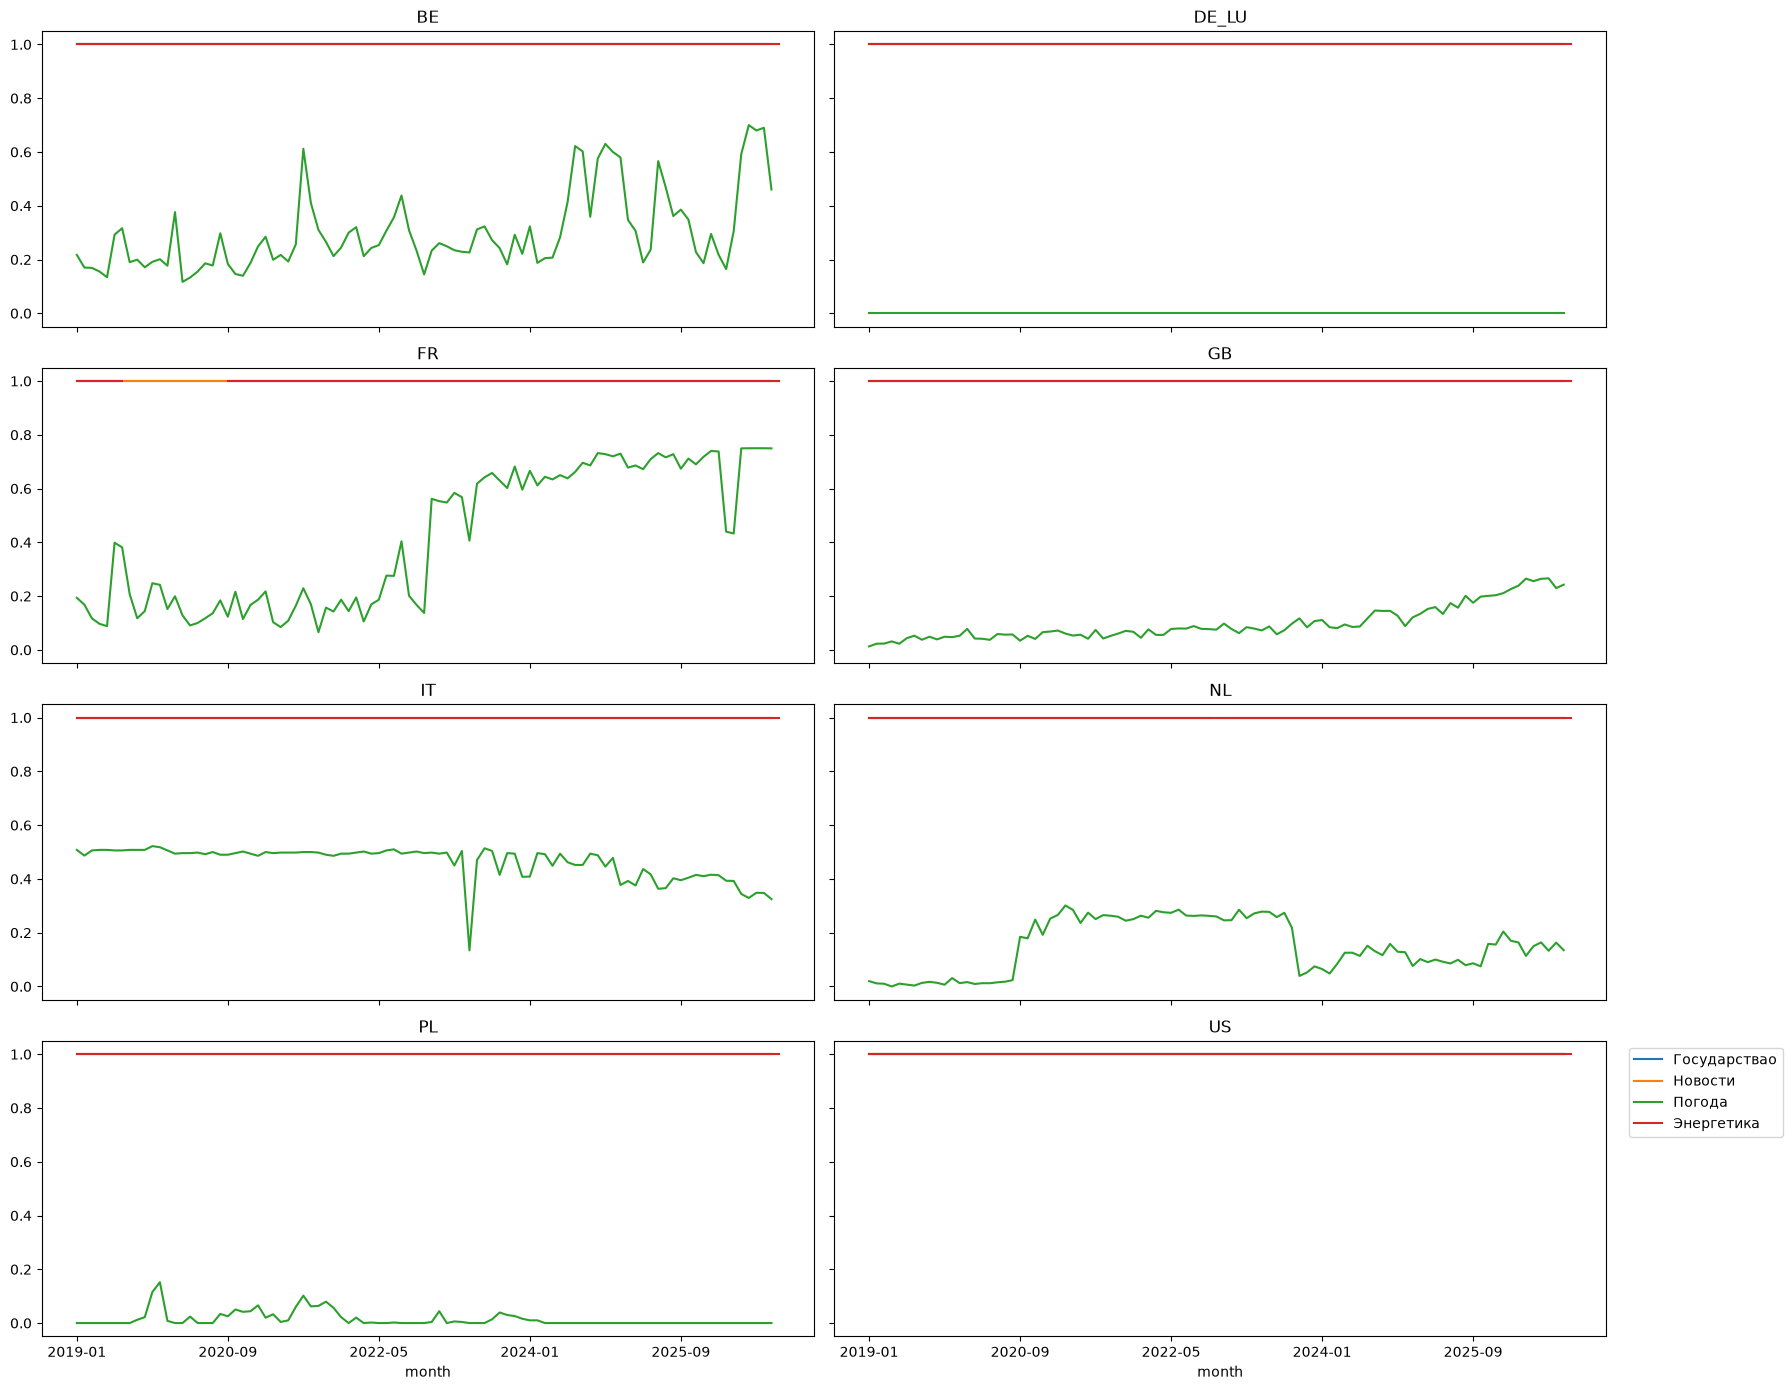

In [72]:
fig,ax=plt.subplots(4,2,figsize=(18, 14),sharex=True,sharey=True)
for i,country in enumerate(country_list):
    text_availability[text_availability["country"]==country].groupby(["month","корпус"])["публикация распознана"].mean().unstack().plot(ax=ax.flat[i],legend=False)
    ax.flat[i].set_title(country)
ax.flat[-1].legend(bbox_to_anchor=(1.02,1),loc="upper left") # без вот этой штуки плохо рисовалось , я так и не поняла почему bbox_to_anchor=(1.02,1) 
plt.tight_layout()
plt.show()

Ну тут подтверждается , что я сказала в прошлой ячейке .Основная проблема с незаполненостью именно в погодных данных.При моделировании уже , учтем это и будем думать , как конкретно решить эту проблему 